# Clasificación Multiescala del Tejido Urbano en el Distrito de Puno (Versión Unificada — Google Colab)

**Curso:** Estructuras de Datos Avanzadas (EDA) — Unidad 2  
**Área Geográfica:** Distrito de Puno, Provincia y Departamento de Puno, Perú (`460.41 km²`)  
**Modelos Obligatorios:** `DecisionTreeClassifier` (**Gini** vs. **Entropía**), `RandomForestClassifier`, `XGBClassifier` (*XGBoost*) y `LGBMClassifier` (*LightGBM*).

---

### Guía rápida para ejecutar con 1 clic en Google Colab (`Entorno de ejecución → Ejecutar todo`)
Este cuaderno carga los datos vectoriales ligeros de Puno (`data_puno_colab.zip`, solo **614 KB**, ya recortados de los ~1.5 GB originales de Perú) directamente desde **Google Drive**:

* **Opción A — Enlace compartido de Google Drive *(Recomendada para compartir el link al ingeniero — funciona desde cualquier cuenta de Google sin permisos adicionales)*:**
  1. Sube el archivo `data_puno_colab.zip` (o la carpeta `data_puno/`) a tu Google Drive.
  2. Haz clic derecho → **Compartir → Cualquier persona con el enlace (Lector)** y copia el enlace.
  3. Pega ese enlace en la variable `GOOGLE_DRIVE_ZIP_URL` (o `GOOGLE_DRIVE_FOLDER_URL`) en la celda de abajo.
* **Opción B — Desde tu propio Google Drive montado:**
  Si tienes la carpeta en `Mi unidad/Zonas_Puno/data_puno`, deja ambas URLs vacías (`""`) y el cuaderno montará tu Drive automáticamente con `drive.mount('/content/drive')`.
* **Opción C — Ejecución local (VS Code / Jupyter):**
  Si no estás en Colab, el cuaderno detecta automáticamente la carpeta local `./data_puno/`.

---

### Estructura del Cuaderno Unificado
* **Configuración:** Instalación ligera en Colab + Carga automática desde Google Drive.
* **Parte 1:** Delimitación Espacial, Formato Shapefile y Descripción de Datos Crudos de Puno.
* **Parte 2:** **Nivel Micro (Edificaciones)** — 11 features con `cKDTree`, Validación 75/25 + 5-Fold CV, Matemática de los 4 Modelos, **8 Árboles Completos (sin `[...]`)**, Matrices de Confusión e Imputación + Mapa Folium.
* **Parte 3:** **Nivel Macro (Zonificación 250m × 250m)** — Grilla espacial, 17 features integrando el Nivel Micro, Balanceo de Clases ($w_k$), **8 Árboles Completos**, Matrices 4×4 e Imputación + Mapa Folium.
* **Parte 4:** **Evaluación Comparativa Global** — Micro vs. Macro, Gini vs. Entropía (*overfitting*), Concordancia (Cohen's Kappa), Aciertos/Discrepancias, Coherencia Multiescala, Lámina Cartográfica Final y Mapa Integrado Folium.

## 0. Configuración de Entorno y Carga Automática desde Google Drive

In [1]:
import sys
import os
import zipfile
import subprocess
from pathlib import Path

EN_COLAB = 'google.colab' in sys.modules

# ==============================================================================
# CONFIGURACIÓN DE GOOGLE DRIVE (Elige Opción A o B si estás en Google Colab)
# ==============================================================================
# Opción A1 (RECOMENDADA para compartir con el ingeniero): pega aquí el link compartido de 'data_puno_colab.zip'
GOOGLE_DRIVE_ZIP_URL = ""

# Opción A2 (Alternativa): pega aquí el link compartido de la carpeta 'data_puno' en Google Drive
GOOGLE_DRIVE_FOLDER_URL = ""

# Opción B (Si las URLs están vacías en Colab): ruta dentro de tu propio Google Drive montado
RUTA_DRIVE_PROPIO = "/content/drive/MyDrive/Zonas_Puno/data_puno"
# ==============================================================================

if EN_COLAB:
    print("Entorno detectado: Google Colab. Verificando librerías necesarias...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "geopandas", "pyogrio", "shapely", "scipy", "scikit-learn",
        "xgboost", "lightgbm", "matplotlib", "seaborn", "folium", "gdown"
    ])
    import gdown

    DIR_FIGURES = Path("/content/figures")
    DIR_FIGURES.mkdir(parents=True, exist_ok=True)

    if GOOGLE_DRIVE_ZIP_URL.strip():
        DIR_DATA_PUNO = Path("/content/data_puno")
        if not (DIR_DATA_PUNO / "puno_distrito_boundary.geojson").exists():
            print("Descargando data_puno_colab.zip desde enlace público de Google Drive...")
            zip_dest = "/content/data_puno_colab.zip"
            gdown.download(url=GOOGLE_DRIVE_ZIP_URL.strip(), output=zip_dest, quiet=False, fuzzy=True)
            with zipfile.ZipFile(zip_dest, 'r') as zf:
                zf.extractall("/content")
            # Soporta zip con o sin subcarpeta 'data_puno/'
            if not (DIR_DATA_PUNO / "puno_distrito_boundary.geojson").exists():
                DIR_DATA_PUNO.mkdir(parents=True, exist_ok=True)
                for gj in Path("/content").glob("puno_*.geojson"):
                    gj.rename(DIR_DATA_PUNO / gj.name)
    elif GOOGLE_DRIVE_FOLDER_URL.strip():
        DIR_DATA_PUNO = Path("/content/data_puno")
        if not (DIR_DATA_PUNO / "puno_distrito_boundary.geojson").exists():
            print("Descargando carpeta data_puno desde enlace público de Google Drive...")
            DIR_DATA_PUNO.mkdir(parents=True, exist_ok=True)
            gdown.download_folder(url=GOOGLE_DRIVE_FOLDER_URL.strip(), output=str(DIR_DATA_PUNO), quiet=False)
    else:
        from google.colab import drive
        print("Montando tu Google Drive en /content/drive ...")
        drive.mount('/content/drive')
        DIR_DATA_PUNO = Path(RUTA_DRIVE_PROPIO)
else:
    print("Entorno detectado: Ejecución Local.")
    DIR_DATA_PUNO = Path("data_puno") if Path("data_puno").exists() else Path("../data_puno")
    DIR_FIGURES = Path("figures") if Path("data_puno").exists() else Path("../figures")
    DIR_FIGURES.mkdir(parents=True, exist_ok=True)

CAPAS_REQUERIDAS = [
    "puno_distrito_boundary.geojson", "puno_buildings.geojson", "puno_landuse.geojson",
    "puno_roads.geojson", "puno_pois.geojson", "puno_pois_a.geojson",
    "puno_transport.geojson", "puno_water_a.geojson", "puno_waterways.geojson"
]
faltantes = [f for f in CAPAS_REQUERIDAS if not (DIR_DATA_PUNO / f).exists()]
if faltantes:
    raise FileNotFoundError(
        f"Faltan archivos base en {DIR_DATA_PUNO.resolve()}: {faltantes}\n"
        "Sube 'data_puno_colab.zip' a Google Drive y pega su enlace compartido en GOOGLE_DRIVE_ZIP_URL, "
        "o coloca la carpeta 'data_puno/' en tu Google Drive en RUTA_DRIVE_PROPIO."
    )

print(f"OK — Las 9 capas GeoJSON de Puno están listas en: {DIR_DATA_PUNO.resolve()}")
print(f"Carpeta de figuras (300 DPI): {DIR_FIGURES.resolve()}")

Entorno detectado: Ejecución Local.
OK — Las 9 capas GeoJSON de Puno están listas en: C:\Users\ronim\.gemini\antigravity\brain\78f47f65-46bb-41da-8f4c-8528604246a0\scratch\colab_sandbox\data_puno
Carpeta de figuras (300 DPI): C:\Users\ronim\.gemini\antigravity\brain\78f47f65-46bb-41da-8f4c-8528604246a0\scratch\colab_sandbox\figures


In [2]:
import time
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, box
from scipy.spatial import cKDTree

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle, FancyBboxPatch
from matplotlib.lines import Line2D
import seaborn as sns
import folium
from folium.plugins import Fullscreen, MiniMap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, cohen_kappa_score
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'axes.edgecolor': '#bdc3c7',
    'grid.alpha': 0.35
})

CRS_GEO = "EPSG:4326"      # WGS 84 (lat/lon en grados) -> GeoJSON y Folium
CRS_METRICO = "EPSG:32719" # WGS 84 / UTM Zona 19 Sur (metros) -> áreas y distancias reales

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


---
# PARTE 1: Delimitación Espacial y Descripción de Datos Crudos del Distrito de Puno

### ¿Qué son los archivos originales de OpenStreetMap (`.shp`, `.dbf`, `.shx`, `.prj`, `.cpg`)?
Los datos crudos descargados de **Geofabrik (OpenStreetMap — Perú, ~1.5 GB)** utilizan el formato estándar **ESRI Shapefile**, compuesto por 5 archivos inseparables:

| Extensión | Función | Contenido |
| :--- | :--- | :--- |
| **`.shp`** | Geometrías | Coordenadas de polígonos, líneas o puntos (edificios, vías, parques). |
| **`.dbf`** | Tabla de atributos | Columnas descriptivas asociadas a cada geometría (`osm_id`, `name`, `fclass`, `type`). |
| **`.shx`** | Índice posicional | Conecta rápidamente cada geometría del `.shp` con su fila en el `.dbf`. |
| **`.prj`** | Proyección | Sistema de Referencia de Coordenadas (`WGS 84 / EPSG:4326`). |
| **`.cpg`** | Codificación | Codificación de caracteres (`UTF-8`) para tildes y *ñ*. |

Mediante **Spatial Index Bounding Box Filter + intersección exacta** con el límite distrital oficial de Puno (`admin_level8`, OSM ID `1913513`), recortamos y unificamos cada capa en archivos `.geojson` ligeros (614 KB comprimidos) dentro de `data_puno/`.  
Para calcular áreas en $\text{m}^2$/$\text{km}^2$ y distancias en metros sin distorsión, proyectamos todas las capas a **`EPSG:32719` (UTM Zona 19 Sur)**.

In [3]:
# Cargar las 9 capas GeoJSON de Puno
puno_distrito = gpd.read_file(DIR_DATA_PUNO / "puno_distrito_boundary.geojson")
gdf_buildings = gpd.read_file(DIR_DATA_PUNO / "puno_buildings.geojson")
gdf_landuse   = gpd.read_file(DIR_DATA_PUNO / "puno_landuse.geojson")
gdf_roads     = gpd.read_file(DIR_DATA_PUNO / "puno_roads.geojson")
gdf_pois      = gpd.read_file(DIR_DATA_PUNO / "puno_pois.geojson")
gdf_pois_a    = gpd.read_file(DIR_DATA_PUNO / "puno_pois_a.geojson")
gdf_transport = gpd.read_file(DIR_DATA_PUNO / "puno_transport.geojson")
gdf_water_a   = gpd.read_file(DIR_DATA_PUNO / "puno_water_a.geojson")
gdf_waterways = gpd.read_file(DIR_DATA_PUNO / "puno_waterways.geojson")

# Proyección métrica oficial (UTM Zona 19 Sur — metros)
puno_utm = puno_distrito.to_crs(CRS_METRICO)
b_raw_utm = gdf_buildings.to_crs(CRS_METRICO)
lu_utm = gdf_landuse.to_crs(CRS_METRICO)
rd_utm = gdf_roads.to_crs(CRS_METRICO)
p_utm  = gdf_pois.to_crs(CRS_METRICO)
pa_utm = gdf_pois_a.to_crs(CRS_METRICO)
tr_utm = gdf_transport.to_crs(CRS_METRICO)
wa_utm = gdf_water_a.to_crs(CRS_METRICO)
ww_utm = gdf_waterways.to_crs(CRS_METRICO)

area_km2 = puno_utm.geometry.area.iloc[0] / 1e6
perimetro_km = puno_utm.geometry.length.iloc[0] / 1000.0
plaza_armas_utm = gpd.GeoSeries([Point(-70.0280, -15.8402)], crs=CRS_GEO).to_crs(CRS_METRICO).iloc[0]

resumen_capas = pd.DataFrame([
    {"Capa": "Límite Distrital", "Archivo": "puno_distrito_boundary.geojson", "Geometría": "Polígono", "Registros": len(puno_distrito), "Métrica Espacial": f"{area_km2:,.2f} km²", "Rol": "Máscara administrativa oficial"},
    {"Capa": "Edificaciones", "Archivo": "puno_buildings.geojson", "Geometría": "Polígonos", "Registros": len(gdf_buildings), "Métrica Espacial": f"{b_raw_utm.geometry.area.sum()/1e6:.2f} km² construidos", "Rol": "Unidad base — Nivel Micro"},
    {"Capa": "Uso de Suelo", "Archivo": "puno_landuse.geojson", "Geometría": "Polígonos", "Registros": len(gdf_landuse), "Métrica Espacial": f"{lu_utm.geometry.area.sum()/1e6:.2f} km² cubiertos", "Rol": "Etiquetas base — Nivel Macro"},
    {"Capa": "Red Vial", "Archivo": "puno_roads.geojson", "Geometría": "Líneas", "Registros": len(gdf_roads), "Métrica Espacial": f"{rd_utm.geometry.length.sum()/1000:,.1f} km totales", "Rol": "Proximidad y densidad vial"},
    {"Capa": "POIs Puntuales", "Archivo": "puno_pois.geojson", "Geometría": "Puntos", "Registros": len(gdf_pois), "Métrica Espacial": f"{gdf_pois['fclass'].nunique()} categorías", "Rol": "Servicios/comercio con cKDTree"},
    {"Capa": "POIs Poligonales", "Archivo": "puno_pois_a.geojson", "Geometría": "Polígonos", "Registros": len(gdf_pois_a), "Métrica Espacial": f"{gdf_pois_a['fclass'].nunique()} categorías", "Rol": "Equipamiento y áreas verdes"},
    {"Capa": "Transporte", "Archivo": "puno_transport.geojson", "Geometría": "Puntos", "Registros": len(gdf_transport), "Métrica Espacial": f"{gdf_transport['fclass'].nunique()} tipos", "Rol": "Distancia a paraderos (cKDTree)"},
    {"Capa": "Cuerpos de Agua", "Archivo": "puno_water_a.geojson", "Geometría": "Polígonos", "Registros": len(gdf_water_a), "Métrica Espacial": "Lago Titicaca / lagunas", "Rol": "Distancia al borde lacustre"},
    {"Capa": "Quebradas y Ríos", "Archivo": "puno_waterways.geojson", "Geometría": "Líneas", "Registros": len(gdf_waterways), "Métrica Espacial": f"{ww_utm.geometry.length.sum()/1000:,.1f} km", "Rol": "Contexto hídrico"}
])

print(f"Distrito de Puno — Superficie oficial: {area_km2:,.2f} km² | Perímetro: {perimetro_km:,.2f} km")
display(resumen_capas)

print("\nMuestra de datos crudos OSM — puno_buildings.geojson:")
muestra_b_cruda = gdf_buildings[gdf_buildings['name'].notna() | gdf_buildings['type'].notna()][
    ['osm_id', 'code', 'fclass', 'name', 'type']
].head(5).copy()
display(muestra_b_cruda)

Distrito de Puno — Superficie oficial: 460.41 km² | Perímetro: 118.30 km


,Capa,Archivo,Geometría,Registros,Métrica Espacial,Rol
0,Límite Distrital,puno_distrito_boundary.geojson,Polígono,1,460.41 km²,Máscara administrativa oficial
1,Edificaciones,puno_buildings.geojson,Polígonos,652,0.30 km² construidos,Unidad base — Nivel Micro
2,Uso de Suelo,puno_landuse.geojson,Polígonos,273,41.35 km² cubiertos,Etiquetas base — Nivel Macro
3,Red Vial,puno_roads.geojson,Líneas,4276,"1,114.2 km totales",Proximidad y densidad vial
4,POIs Puntuales,puno_pois.geojson,Puntos,935,64 categorías,Servicios/comercio con cKDTree
5,POIs Poligonales,puno_pois_a.geojson,Polígonos,330,31 categorías,Equipamiento y áreas verdes
6,Transporte,puno_transport.geojson,Puntos,48,5 tipos,Distancia a paraderos (cKDTree)
7,Cuerpos de Agua,puno_water_a.geojson,Polígonos,9,Lago Titicaca / lagunas,Distancia al borde lacustre
8,Quebradas y Ríos,puno_waterways.geojson,Líneas,30,39.7 km,Contexto hídrico



Muestra de datos crudos OSM — puno_buildings.geojson:


,osm_id,code,fclass,name,type
2,225903400,1500,building,Iglesia de San Juan,church
9,245233060,1500,building,Terminal Terrestre de Puno,NaN
10,245233061,1500,building,Mercado Central,NaN
14,255732549,1500,building,Iglesia Biblica Bautista,NaN
15,315213481,1500,building,Condor,NaN


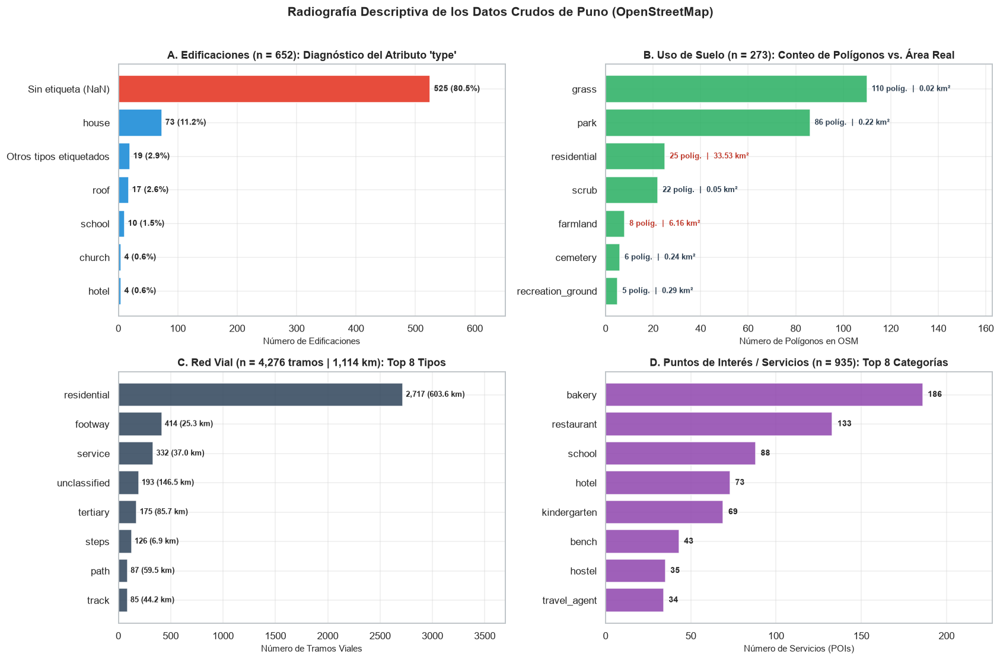

In [4]:
# Radiografía Descriptiva 2×2 de los Datos Crudos de Puno
fig, axes = plt.subplots(2, 2, figsize=(15.5, 10))

# Panel A: Edificaciones (Completitud 'type')
b_types = gdf_buildings['type'].fillna('Sin etiqueta (NaN)')
top_b = b_types.value_counts()
top_b_plot = pd.concat([top_b.head(6), pd.Series({'Otros tipos etiquetados': top_b.iloc[6:].sum()})]).sort_values(ascending=True)
colores_a = ['#e74c3c' if idx == 'Sin etiqueta (NaN)' else '#3498db' for idx in top_b_plot.index]
bars_a = axes[0, 0].barh(top_b_plot.index, top_b_plot.values, color=colores_a, edgecolor='white')
axes[0, 0].set_title("A. Edificaciones (n = 652): Diagnóstico del Atributo 'type'")
axes[0, 0].set_xlabel("Número de Edificaciones")
axes[0, 0].set_xlim(0, top_b_plot.max() * 1.24)
for bar in bars_a:
    w = bar.get_width()
    axes[0, 0].annotate(f"{int(w)} ({w/len(gdf_buildings)*100:.1f}%)", (w + 6, bar.get_y() + bar.get_height()/2),
                        va='center', fontsize=9, fontweight='bold')

# Panel B: Landuse (Polígonos vs Área real km²)
lu_stats = pd.DataFrame({
    'Polígonos': lu_utm['fclass'].value_counts(),
    'Área (km²)': lu_utm.groupby('fclass').apply(lambda g: g.geometry.area.sum() / 1e6)
}).fillna(0)
top_lu = lu_stats.sort_values('Polígonos', ascending=False).head(7).iloc[::-1]
bars_b = axes[0, 1].barh(top_lu.index, top_lu['Polígonos'], color='#27ae60', alpha=0.85, edgecolor='white')
axes[0, 1].set_title("B. Uso de Suelo (n = 273): Conteo de Polígonos vs. Área Real")
axes[0, 1].set_xlabel("Número de Polígonos en OSM")
axes[0, 1].set_xlim(0, top_lu['Polígonos'].max() * 1.48)
for bar, (_, row) in zip(bars_b, top_lu.iterrows()):
    w = bar.get_width()
    axes[0, 1].annotate(f"{int(w)} políg.  |  {row['Área (km²)']:.2f} km²",
                        (w + 2, bar.get_y() + bar.get_height()/2),
                        va='center', fontsize=8.8, fontweight='bold',
                        color='#c0392b' if row['Área (km²)'] > 5 else '#2c3e50')

# Panel C: Red Vial (Top 8 con longitud en km)
rd_stats = pd.DataFrame({
    'Tramos': rd_utm['fclass'].value_counts(),
    'Longitud (km)': rd_utm.groupby('fclass').apply(lambda g: g.geometry.length.sum() / 1000.0)
}).fillna(0)
top_rd = rd_stats.sort_values('Tramos', ascending=False).head(8).iloc[::-1]
bars_c = axes[1, 0].barh(top_rd.index, top_rd['Tramos'], color='#34495e', alpha=0.88, edgecolor='white')
axes[1, 0].set_title(f"C. Red Vial (n = {len(rd_utm):,} tramos | {rd_utm.geometry.length.sum()/1000:,.0f} km): Top 8 Tipos")
axes[1, 0].set_xlabel("Número de Tramos Viales")
axes[1, 0].set_xlim(0, top_rd['Tramos'].max() * 1.36)
for bar, (_, row) in zip(bars_c, top_rd.iterrows()):
    w = bar.get_width()
    axes[1, 0].annotate(f"{int(w):,} ({row['Longitud (km)']:.1f} km)",
                        (w + 30, bar.get_y() + bar.get_height()/2),
                        va='center', fontsize=8.8, fontweight='bold')

# Panel D: POIs (Top 8)
top_pois = gdf_pois['fclass'].value_counts().head(8).iloc[::-1]
bars_d = axes[1, 1].barh(top_pois.index, top_pois.values, color='#8e44ad', alpha=0.85, edgecolor='white')
axes[1, 1].set_title(f"D. Puntos de Interés / Servicios (n = {len(gdf_pois)}): Top 8 Categorías")
axes[1, 1].set_xlabel("Número de Servicios (POIs)")
axes[1, 1].set_xlim(0, top_pois.max() * 1.22)
for bar in bars_d:
    w = bar.get_width()
    axes[1, 1].annotate(f"{int(w)}", (w + 3, bar.get_y() + bar.get_height()/2),
                        va='center', fontsize=9, fontweight='bold')

plt.suptitle("Radiografía Descriptiva de los Datos Crudos de Puno (OpenStreetMap)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "01_radiografia_datos_puno.png", bbox_inches='tight')
plt.show()

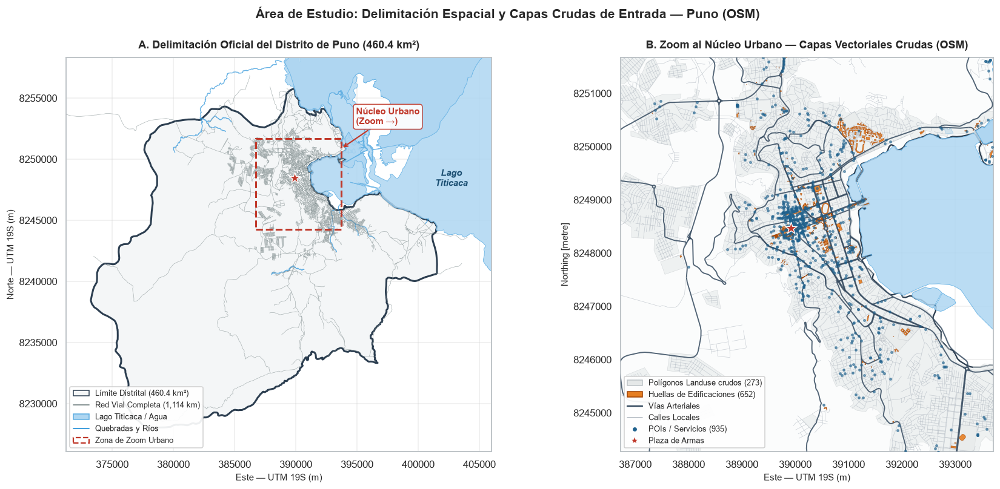

In [5]:
# Mapa Cartográfico de Datos Crudos Recortados (Sin Modelar Todavía)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.4), gridspec_kw={'width_ratios': [1.05, 1]})

px, py = plaza_armas_utm.x, plaza_armas_utm.y
zoom_minx, zoom_maxx = px - 3200, px + 3800
zoom_miny, zoom_maxy = py - 4200, py + 3200

puno_utm.plot(ax=ax1, color='#f4f6f7', edgecolor='#2c3e50', linewidth=2.0, zorder=1)
wa_utm.plot(ax=ax1, color='#aed6f1', edgecolor='#5dade2', linewidth=0.6, alpha=0.85, zorder=2)
ww_utm.plot(ax=ax1, color='#3498db', linewidth=0.9, alpha=0.75, zorder=3)
rd_utm.plot(ax=ax1, color='#7f8c8d', linewidth=0.45, alpha=0.65, zorder=4)

ax1.add_patch(Rectangle((zoom_minx, zoom_miny), zoom_maxx - zoom_minx, zoom_maxy - zoom_miny,
                        linewidth=2.0, edgecolor='#c0392b', facecolor='none', linestyle='--', zorder=6))
ax1.scatter([px], [py], color='#c0392b', marker='*', s=150, edgecolor='white', linewidth=0.8, zorder=7)

bminx, bminy, bmaxx, bmaxy = puno_utm.total_bounds
ax1.set_xlim(bminx - 2000, bmaxx + 4500)
ax1.set_ylim(bminy - 2000, bmaxy + 2500)
ax1.annotate("Núcleo Urbano\n(Zoom →)", xy=(zoom_maxx, zoom_maxy - 800),
             xytext=(zoom_maxx + 1200, zoom_maxy + 1200),
             fontsize=9.5, fontweight='bold', color='#c0392b',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#c0392b', alpha=0.92),
             arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.4))
ax1.text(bmaxx + 1200, bmaxy - 8000, "Lago\nTiticaca", fontsize=10, style='italic',
         fontweight='bold', color='#1b4f72', ha='center', zorder=7)
ax1.set_title(f"A. Delimitación Oficial del Distrito de Puno ({area_km2:,.1f} km²)", pad=10)
ax1.set_xlabel("Este — UTM 19S (m)")
ax1.set_ylabel("Norte — UTM 19S (m)")
ax1.ticklabel_format(style='plain', axis='both')
ax1.legend(handles=[
    mpatches.Patch(facecolor='#f4f6f7', edgecolor='#2c3e50', label='Límite Distrital (460.4 km²)'),
    Line2D([0], [0], color='#7f8c8d', lw=1.2, label='Red Vial Completa (1,114 km)'),
    mpatches.Patch(facecolor='#aed6f1', edgecolor='#5dade2', label='Lago Titicaca / Agua'),
    Line2D([0], [0], color='#3498db', lw=1.2, label='Quebradas y Ríos'),
    mpatches.Patch(facecolor='none', edgecolor='#c0392b', linestyle='--', linewidth=1.5, label='Zona de Zoom Urbano')
], loc='lower left', fontsize=8.5, frameon=True, facecolor='white', framealpha=0.92)

puno_utm.plot(ax=ax2, color='#fbfcfc', edgecolor='#2c3e50', linewidth=1.5, zorder=1)
wa_utm.plot(ax=ax2, color='#aed6f1', edgecolor='#5dade2', linewidth=0.6, alpha=0.85, zorder=2)
lu_utm.plot(ax=ax2, color='#e5e8e8', edgecolor='#bdc3c7', linewidth=0.4, alpha=0.55, zorder=2)
vias_art_set = {'trunk', 'primary', 'primary_link', 'secondary', 'secondary_link', 'tertiary', 'tertiary_link'}
rd_utm[~rd_utm['fclass'].isin(vias_art_set)].plot(ax=ax2, color='#aeb6bf', linewidth=0.45, alpha=0.65, zorder=4)
rd_utm[rd_utm['fclass'].isin(vias_art_set)].plot(ax=ax2, color='#34495e', linewidth=1.25, alpha=0.85, zorder=5)
b_raw_utm.plot(ax=ax2, color='#e67e22', edgecolor='#a04000', linewidth=0.35, alpha=0.9, zorder=6)
p_utm.plot(ax=ax2, color='#1f618d', markersize=5, alpha=0.55, zorder=7)
ax2.scatter([px], [py], color='#c0392b', marker='*', s=180, edgecolor='white', linewidth=0.9, zorder=8)
ax2.set_xlim(zoom_minx, zoom_maxx)
ax2.set_ylim(zoom_miny, zoom_maxy)
ax2.set_title("B. Zoom al Núcleo Urbano — Capas Vectoriales Crudas (OSM)", pad=10)
ax2.set_xlabel("Este — UTM 19S (m)")
ax2.ticklabel_format(style='plain', axis='both')
ax2.legend(handles=[
    mpatches.Patch(facecolor='#e5e8e8', edgecolor='#bdc3c7', label='Polígonos Landuse crudos (273)'),
    mpatches.Patch(facecolor='#e67e22', edgecolor='#a04000', label=f'Huellas de Edificaciones ({len(b_raw_utm)})'),
    Line2D([0], [0], color='#34495e', lw=1.6, label='Vías Arteriales'),
    Line2D([0], [0], color='#aeb6bf', lw=1.0, label='Calles Locales'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#1f618d', markersize=5.5, label=f'POIs / Servicios ({len(p_utm)})'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#c0392b', markersize=10, label='Plaza de Armas')
], loc='lower left', fontsize=8.2, frameon=True, facecolor='white', framealpha=0.93)

plt.suptitle("Área de Estudio: Delimitación Espacial y Capas Crudas de Entrada — Puno (OSM)", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "01_mapa_cartografico_puno.png", bbox_inches='tight')
plt.show()

---
# PARTE 2: Nivel Micro — Clasificación de Edificaciones en el Distrito de Puno

## 2.1. Etiquetado Verificable ($y$) e Ingeniería de 11 Variables ($X$) con `cKDTree`
Construimos **184 edificaciones verificadas** en 3 clases (`Residencial`, `Institucional`, `Comercial_Servicios`) combinando `name`, `type` y POIs internos, y extraemos **11 variables predictoras ($X$)** morfológicas y espaciales usando **`cKDTree` ($O(\log N)$)** con **cero fuga de datos** (excluyendo POIs internos en `pois_entorno_300m`).

In [6]:
b_utm = b_raw_utm.copy()
roads_utm = rd_utm.copy()
pois_utm = p_utm.copy()

# Etiquetado verificable (3 clases)
join_poi = gpd.sjoin(b_utm[['osm_id', 'geometry']], pois_utm[['fclass', 'geometry']], how='left', predicate='intersects')
poi_por_edificio = join_poi.dropna(subset=['fclass']).groupby('osm_id')['fclass'].first()
b_utm['poi_interno'] = b_utm['osm_id'].map(poi_por_edificio)

MAPA_TYPE = {
    'house': 'Residencial',
    'hotel': 'Comercial_Servicios', 'retail': 'Comercial_Servicios',
    'industrial': 'Comercial_Servicios', 'warehouse': 'Comercial_Servicios',
    'train_station': 'Comercial_Servicios', 'greenhouse': 'Comercial_Servicios',
    'school': 'Institucional', 'university': 'Institucional',
    'church': 'Institucional', 'chapel': 'Institucional',
    'stadium': 'Institucional', 'civic': 'Institucional'
}
MAPA_POI = {
    'hotel': 'Comercial_Servicios', 'restaurant': 'Comercial_Servicios',
    'hostel': 'Comercial_Servicios', 'cafe': 'Comercial_Servicios',
    'atm': 'Comercial_Servicios', 'bank': 'Comercial_Servicios',
    'guesthouse': 'Comercial_Servicios', 'bar': 'Comercial_Servicios',
    'laundry': 'Comercial_Servicios', 'convenience': 'Comercial_Servicios',
    'tourist_info': 'Comercial_Servicios', 'marketplace': 'Comercial_Servicios',
    'clothes': 'Comercial_Servicios', 'bakery': 'Comercial_Servicios',
    'consulate': 'Institucional', 'dentist': 'Institucional',
    'museum': 'Institucional', 'college': 'Institucional',
    'hospital': 'Institucional', 'library': 'Institucional',
    'doctors': 'Institucional', 'clinic': 'Institucional',
    'school': 'Institucional', 'artwork': 'Institucional'
}
KEYWORDS_COMERCIAL = ['mercado', 'internet', 'bitel', 'frutería', 'hostel', 'hotel', 'terminal', 'hacienda', 'tienda', 'banco', 'condor']
KEYWORDS_INSTITUCIONAL = [
    'iglesia', 'bomberos', 'agencia agraria', 'comisaría', 'care', 'ong', 'inei', 'facultad',
    'centro de salud', 'quisco', 'hospital', 'colegio', 'sanidad', 'capilla', 'santuario',
    'santuiario', 'autoridad', 'sunarp', 'crematorio', 'dirección regional',
    'seguridad ciudadana', 'catedral', 'municipalidad', 'gobierno regional'
]

def asignar_clase_edificio(row):
    if pd.notnull(row['name']):
        nombre = str(row['name']).lower()
        if any(k in nombre for k in KEYWORDS_INSTITUCIONAL):
            return 'Institucional'
        if any(k in nombre for k in KEYWORDS_COMERCIAL):
            return 'Comercial_Servicios'
    if pd.notnull(row['type']) and row['type'] in MAPA_TYPE:
        return MAPA_TYPE[row['type']]
    if pd.notnull(row['poi_interno']) and row['poi_interno'] in MAPA_POI:
        return MAPA_POI[row['poi_interno']]
    return np.nan

b_utm['clase_uso'] = b_utm.apply(asignar_clase_edificio, axis=1)

# Ingeniería de 11 Features (Morfología + cKDTree)
b_utm['area_m2'] = b_utm.geometry.area
b_utm['perimetro_m'] = b_utm.geometry.length
b_utm['compacidad'] = (4 * np.pi * b_utm['area_m2']) / (b_utm['perimetro_m'] ** 2 + 1e-9)

def calcular_aspect_ratio_y_vertices(geom):
    if geom.geom_type == 'Polygon':
        n_vert = len(geom.exterior.coords) - 1
    elif geom.geom_type == 'MultiPolygon':
        n_vert = sum(len(p.exterior.coords) - 1 for p in geom.geoms)
    else:
        n_vert = 0
    rect = geom.minimum_rotated_rectangle
    if rect.geom_type != 'Polygon':
        return 1.0, n_vert
    coords = list(rect.exterior.coords)
    l1 = Point(coords[0]).distance(Point(coords[1]))
    l2 = Point(coords[1]).distance(Point(coords[2]))
    return max(l1, l2) / (min(l1, l2) + 1e-6), n_vert

res_forma = b_utm.geometry.apply(calcular_aspect_ratio_y_vertices)
b_utm['relacion_aspecto'] = [r[0] for r in res_forma]
b_utm['num_vertices'] = [r[1] for r in res_forma]

centroides_b = b_utm.geometry.centroid
coords_b = np.column_stack([centroides_b.x, centroides_b.y])
b_utm['dist_plaza_armas_m'] = centroides_b.distance(plaza_armas_utm)

tree_edif = cKDTree(coords_b)
dist_vec, _ = tree_edif.query(coords_b, k=2)
b_utm['dist_vecino_cercano_m'] = dist_vec[:, 1]
b_utm['densidad_edificios_150m'] = [len(v) - 1 for v in tree_edif.query_ball_point(coords_b, r=150.0)]

coords_pois = np.column_stack([pois_utm.geometry.x, pois_utm.geometry.y])
tree_pois = cKDTree(coords_pois)
pois_300_idx = tree_pois.query_ball_point(coords_b, r=300.0)
b_utm['pois_entorno_300m'] = [
    sum(1 for j in idxs if b_utm.geometry.iloc[i].distance(pois_utm.geometry.iloc[j]) > 1.0)
    for i, idxs in enumerate(pois_300_idx)
]

MAPA_JERARQUIA_VIA = {
    'trunk': 3, 'primary': 3, 'primary_link': 3, 'secondary': 3, 'secondary_link': 3,
    'tertiary': 2, 'tertiary_link': 2,
    'residential': 1, 'unclassified': 1, 'living_street': 1, 'service': 1,
    'pedestrian': 0, 'footway': 0, 'steps': 0, 'path': 0, 'track': 0
}
roads_utm['jerarquia'] = roads_utm['fclass'].map(MAPA_JERARQUIA_VIA).fillna(1)
nearest_road = gpd.sjoin_nearest(
    b_utm[['osm_id', 'geometry']], roads_utm[['jerarquia', 'geometry']],
    how='left', distance_col='dist_via_cercana_m'
).drop_duplicates(subset='osm_id')
b_utm['dist_via_cercana_m'] = b_utm['osm_id'].map(nearest_road.set_index('osm_id')['dist_via_cercana_m'])
b_utm['jerarquia_via'] = b_utm['osm_id'].map(nearest_road.set_index('osm_id')['jerarquia'])

FEATURES_MICRO = [
    'area_m2', 'perimetro_m', 'compacidad', 'relacion_aspecto', 'num_vertices',
    'dist_plaza_armas_m', 'dist_via_cercana_m', 'jerarquia_via',
    'densidad_edificios_150m', 'dist_vecino_cercano_m', 'pois_entorno_300m'
]

df_micro = b_utm[['osm_id', 'name', 'type', 'clase_uso'] + FEATURES_MICRO].copy()
df_micro.to_csv(DIR_DATA_PUNO / "dataset_micro_edificaciones.csv", index=False)

print(f"Dataset Micro generado: {len(df_micro)} filas | Verificadas: {df_micro['clase_uso'].notna().sum()} | A predecir: {df_micro['clase_uso'].isna().sum()}")
muestra_mi = (
    df_micro.dropna(subset=['clase_uso']).groupby('clase_uso', group_keys=False).head(2)
    [['name', 'area_m2', 'perimetro_m', 'compacidad', 'dist_plaza_armas_m', 'densidad_edificios_150m', 'pois_entorno_300m', 'clase_uso']].copy()
)
muestra_mi['name'] = muestra_mi['name'].fillna('Sin nombre (vivienda)')
display(
    muestra_mi.style
    .set_caption("Ejemplos reales — Dataset Nivel Micro (columna resaltada = Variable Objetivo y)")
    .set_properties(subset=['clase_uso'], **{'background-color': '#d4efdf', 'color': '#145a32', 'font-weight': 'bold'})
    .format({'area_m2': '{:.1f}', 'perimetro_m': '{:.1f}', 'compacidad': '{:.2f}', 'dist_plaza_armas_m': '{:.1f}'})
)

Dataset Micro generado: 652 filas | Verificadas: 184 | A predecir: 468


,name,area_m2,perimetro_m,compacidad,dist_plaza_armas_m,densidad_edificios_150m,pois_entorno_300m,clase_uso
2,Iglesia de San Juan,1250.0,205.5,0.37,268.8,1,193,Institucional
9,Terminal Terrestre de Puno,3293.2,401.5,0.26,1227.4,11,18,Comercial_Servicios
10,Mercado Central,2858.4,223.2,0.72,338.4,4,200,Comercial_Servicios
14,Iglesia Biblica Bautista,834.9,134.3,0.58,1024.3,2,34,Institucional
230,Sin nombre (vivienda),97.0,40.8,0.73,924.6,21,21,Residencial
231,Sin nombre (vivienda),86.7,37.8,0.76,926.8,23,23,Residencial


## 2.2. Validación (`75% Train / 25% Test` + `5-Fold CV`) vs. Imputación Final

* **NO** se usa el 25% de Test para imputar los edificios sin etiqueta: el **25% Test (`46` edificios)** son datos **verificados** cuya etiqueta se oculta para funcionar como **"Examen Final"** (Matriz de Confusión).
* La **Validación Cruzada Estratificada (`5-Fold CV`)** rota 5 bloques estrictamente sobre el **75% de entrenamiento (`138` edificios)** para garantizar que el ganador no dependa de una sola partición.
* Solo **después** de elegir al modelo ganador, lo reentrenamos con el **100% de las `184` verificadas** para predecir las **`468` edificaciones sin etiqueta**.

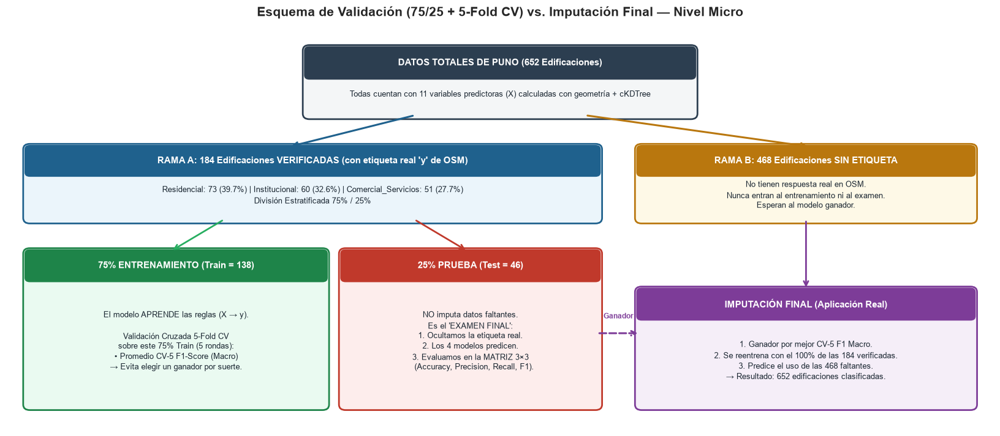

In [7]:
df_mi_lab = df_micro.dropna(subset=['clase_uso']).copy().reset_index(drop=True)
X_mi = df_mi_lab[FEATURES_MICRO].copy()
le_mi = LabelEncoder()
y_mi = le_mi.fit_transform(df_mi_lab['clase_uso'])
clases_mi = list(le_mi.classes_)

X_mi_train, X_mi_test, y_mi_train, y_mi_test = train_test_split(
    X_mi, y_mi, test_size=0.25, random_state=42, stratify=y_mi
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Diagrama Visual de Validación vs Imputación (Micro)
fig, ax = plt.subplots(figsize=(15, 6.6))
ax.set_xlim(0, 15); ax.set_ylim(0, 7.2); ax.axis('off')

def dibujar_caja(ax_obj, x, y, w, h, titulo, texto, bg, edge, hdr_h=0.45):
    ax_obj.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1", facecolor=bg, edgecolor=edge, linewidth=1.8))
    ax_obj.add_patch(FancyBboxPatch((x, y + h - hdr_h), w, hdr_h, boxstyle="round,pad=0.08", facecolor=edge, edgecolor='none'))
    ax_obj.text(x + w/2, y + h - hdr_h/2, titulo, color='white', fontsize=9.8, fontweight='bold', ha='center', va='center')
    ax_obj.text(x + w/2, y + (h - hdr_h)/2, texto, color='#1c2833', fontsize=8.8, ha='center', va='center', linespacing=1.35)

dibujar_caja(ax, 4.6, 5.75, 5.8, 1.15, "DATOS TOTALES DE PUNO (652 Edificaciones)",
             "Todas cuentan con 11 variables predictoras (X) calculadas con geometría + cKDTree", '#f4f6f7', '#2c3e50')
ax.annotate('', xy=(4.3, 5.15), xytext=(6.2, 5.72), arrowprops=dict(arrowstyle='->', lw=2.0, color='#1f618d'))
ax.annotate('', xy=(12.2, 5.15), xytext=(8.8, 5.72), arrowprops=dict(arrowstyle='->', lw=2.0, color='#b9770e'))
dibujar_caja(ax, 0.35, 3.85, 8.6, 1.25, "RAMA A: 184 Edificaciones VERIFICADAS (con etiqueta real 'y' de OSM)",
             "Residencial: 73 (39.7%) | Institucional: 60 (32.6%) | Comercial_Servicios: 51 (27.7%)\nDivisión Estratificada 75% / 25%",
             '#ebf5fb', '#1f618d', hdr_h=0.42)
ax.annotate('', xy=(2.5, 3.25), xytext=(3.3, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#27ae60'))
ax.annotate('', xy=(7.0, 3.25), xytext=(6.2, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#c0392b'))
dibujar_caja(ax, 0.35, 0.45, 4.45, 2.75, "75% ENTRENAMIENTO (Train = 138)",
             "El modelo APRENDE las reglas (X → y).\n\nValidación Cruzada 5-Fold CV\nsobre este 75% Train (5 rondas):\n• Promedio CV-5 F1-Score (Macro)\n→ Evita elegir un ganador por suerte.",
             '#eafaf1', '#1e8449', hdr_h=0.44)
dibujar_caja(ax, 5.15, 0.45, 3.8, 2.75, "25% PRUEBA (Test = 46)",
             "NO imputa datos faltantes.\nEs el 'EXAMEN FINAL':\n1. Ocultamos la etiqueta real.\n2. Los 4 modelos predicen.\n3. Evaluamos en la MATRIZ 3×3\n   (Accuracy, Precision, Recall, F1).",
             '#fdedec', '#c0392b', hdr_h=0.44)
dibujar_caja(ax, 9.65, 3.85, 5.0, 1.25, "RAMA B: 468 Edificaciones SIN ETIQUETA",
             "No tienen respuesta real en OSM.\nNunca entran al entrenamiento ni al examen.\nEsperan al modelo ganador.",
             '#fef9e7', '#b9770e', hdr_h=0.42)
ax.annotate('', xy=(12.15, 2.55), xytext=(12.15, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#7d3c98'))
ax.annotate('', xy=(9.62, 1.75), xytext=(8.98, 1.75), arrowprops=dict(arrowstyle='->', lw=2.0, color='#7d3c98', ls='--'))
ax.text(9.30, 2.02, "Ganador", fontsize=8, fontweight='bold', color='#7d3c98', ha='center')
dibujar_caja(ax, 9.65, 0.45, 5.0, 2.05, "IMPUTACIÓN FINAL (Aplicación Real)",
             "1. Ganador por mejor CV-5 F1 Macro.\n2. Se reentrena con el 100% de las 184 verificadas.\n3. Predice el uso de las 468 faltantes.\n→ Resultado: 652 edificaciones clasificadas.",
             '#f5eef8', '#7d3c98', hdr_h=0.44)
plt.suptitle("Esquema de Validación (75/25 + 5-Fold CV) vs. Imputación Final — Nivel Micro", fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "02_flujo_validacion_micro.png", bbox_inches='tight')
plt.show()

## 2.3. Respaldo Matemático de los 4 Algoritmos

1. **`DecisionTreeClassifier` (Gini vs. Entropía):** maximiza la Ganancia de Información $IG(t, f) = I(t) - \left(\frac{N_L}{N} I(t_L) + \frac{N_R}{N} I(t_R)\right)$ usando:
   * **Gini:** $G(t) = 1 - \sum_{k=1}^{K} p_k^2$  &nbsp;&nbsp;|&nbsp;&nbsp; **Entropía:** $H(t) = -\sum_{k=1}^{K} p_k \log_2(p_k)$
2. **`RandomForestClassifier` (Bagging en paralelo):** entrena $B$ árboles independientes con muestreo *Bootstrap* y $m \approx \sqrt{p}$ variables por corte; predice por promedio de probabilidades $\hat{y}(x) = \arg\max_k \frac{1}{B} \sum_{b=1}^{B} P_b(y=k \mid x)$, reduciendo la varianza a $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$.
3. **`XGBClassifier` (Gradient Boosting *level-wise*):** construye árboles secuenciales $\hat{y}_i^{(t)} = \hat{y}_i^{(t-1)} + \eta f_t(x_i)$ minimizando una función regularizada vía expansión de Taylor de 2.º orden ($g_i, h_i$):
   $$w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}, \qquad \text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right] - \gamma$$
4. **`LGBMClassifier` (Histogramas + *Leaf-wise*):** agrupa valores en histogramas ($O(\text{bins})$) y expande globalmente la hoja con mayor ganancia $j^* = \arg\max_{j \in \text{hojas}} \text{Gain}(j)$, generando árboles asimétricos veloces y precisos.

In [8]:
# Poda (max_depth) Gini vs Entropía + Entrenamiento de los 4 Modelos (Nivel Micro)
prof_mi = range(2, 11)
sc_g_mi = [cross_val_score(DecisionTreeClassifier(criterion='gini', max_depth=d, min_samples_leaf=3, random_state=42), X_mi_train, y_mi_train, cv=cv, scoring='f1_macro').mean() for d in prof_mi]
sc_e_mi = [cross_val_score(DecisionTreeClassifier(criterion='entropy', max_depth=d, min_samples_leaf=3, random_state=42), X_mi_train, y_mi_train, cv=cv, scoring='f1_macro').mean() for d in prof_mi]
mejor_d_g_mi = list(prof_mi)[int(np.argmax(sc_g_mi))]
mejor_d_e_mi = list(prof_mi)[int(np.argmax(sc_e_mi))]

def crear_modelos_micro():
    return {
        'DecisionTree (Gini)': DecisionTreeClassifier(criterion='gini', max_depth=mejor_d_g_mi, min_samples_leaf=3, random_state=42),
        'DecisionTree (Entropía)': DecisionTreeClassifier(criterion='entropy', max_depth=mejor_d_e_mi, min_samples_leaf=3, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=2, random_state=42, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42),
        'LightGBM': LGBMClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, num_leaves=15, min_child_samples=10, random_state=42, verbose=-1)
    }

res_mi_list, preds_mi_test, modelos_mi_fit = [], {}, {}
for nombre, modelo in crear_modelos_micro().items():
    cv_f1 = cross_val_score(modelo, X_mi_train, y_mi_train, cv=cv, scoring='f1_macro').mean()
    cv_acc = cross_val_score(modelo, X_mi_train, y_mi_train, cv=cv, scoring='accuracy').mean()
    t0 = time.perf_counter()
    modelo.fit(X_mi_train, y_mi_train)
    t_ms = (time.perf_counter() - t0) * 1000
    yp = modelo.predict(X_mi_test)
    preds_mi_test[nombre] = yp
    modelos_mi_fit[nombre] = modelo
    res_mi_list.append({
        'Modelo': nombre,
        'Test Accuracy': accuracy_score(y_mi_test, yp),
        'Test Precision (Macro)': precision_score(y_mi_test, yp, average='macro', zero_division=0),
        'Test Recall (Macro)': recall_score(y_mi_test, yp, average='macro', zero_division=0),
        'Test F1 (Macro)': f1_score(y_mi_test, yp, average='macro', zero_division=0),
        'CV-5 Accuracy': cv_acc,
        'CV-5 F1 (Macro)': cv_f1,
        'Tiempo Train (ms)': t_ms
    })

df_resultados_micro = pd.DataFrame(res_mi_list).sort_values(by='CV-5 F1 (Macro)', ascending=False)
df_resultados_micro.to_csv(DIR_DATA_PUNO / "resultados_micro_modelos.csv", index=False)
print(f"Profundidad óptima Micro -> Gini: {mejor_d_g_mi} | Entropía: {mejor_d_e_mi}")
display(df_resultados_micro.round(4))

Profundidad óptima Micro -> Gini: 2 | Entropía: 2


,Modelo,Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro),CV-5 Accuracy,CV-5 F1 (Macro),Tiempo Train (ms)
3,XGBoost,0.7826,0.7665,0.7675,0.7593,0.7540,0.7275,249.9861
2,Random Forest,0.8261,0.8343,0.8188,0.8046,0.7540,0.7264,440.4117
0,DecisionTree (Gini),0.7826,0.8295,0.7744,0.7498,0.7386,0.7115,1.7979
1,DecisionTree (Entropía),0.7826,0.8295,0.7744,0.7498,0.7315,0.7013,1.6534
4,LightGBM,0.8261,0.8119,0.8085,0.8087,0.7251,0.6882,47.6921


## 2.4. Visualización Completa de los Árboles en Nivel Micro (Sin Recortes `(...)`)

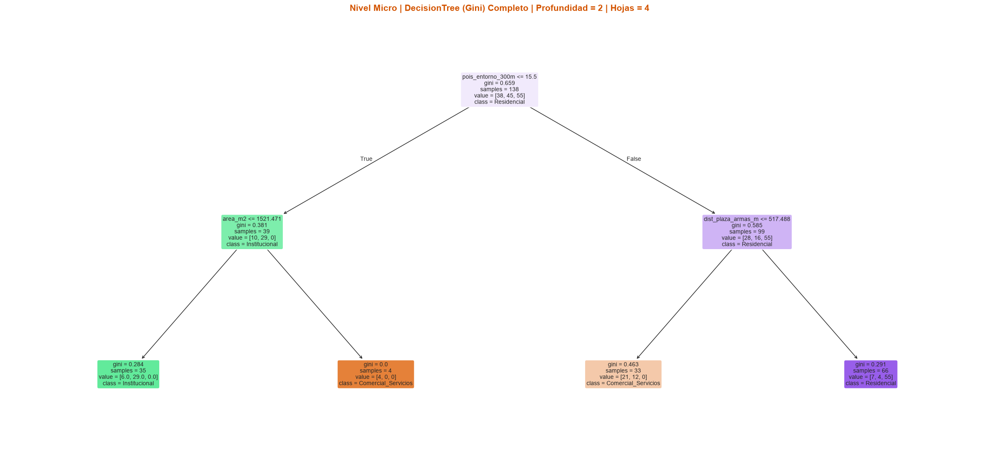

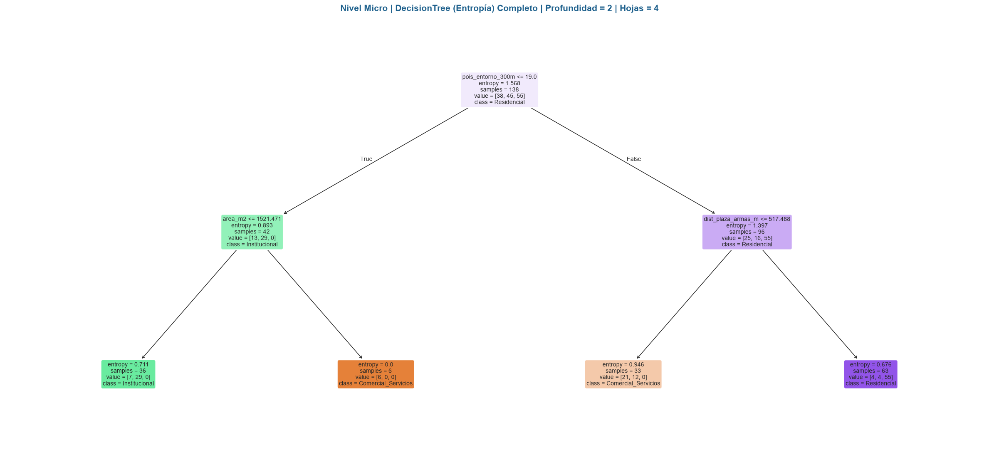

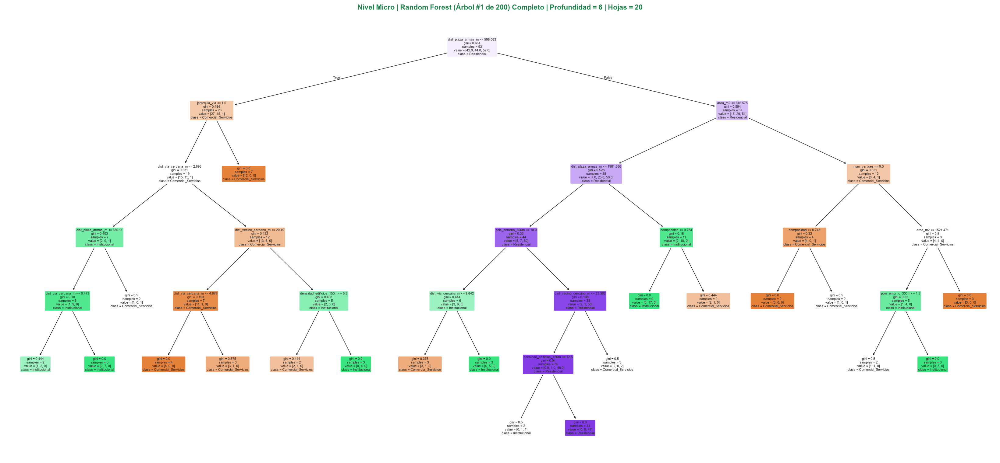

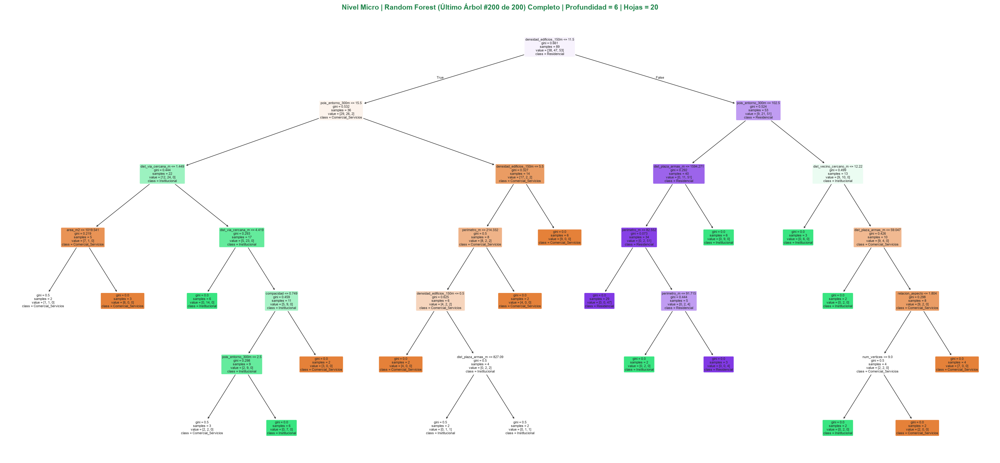

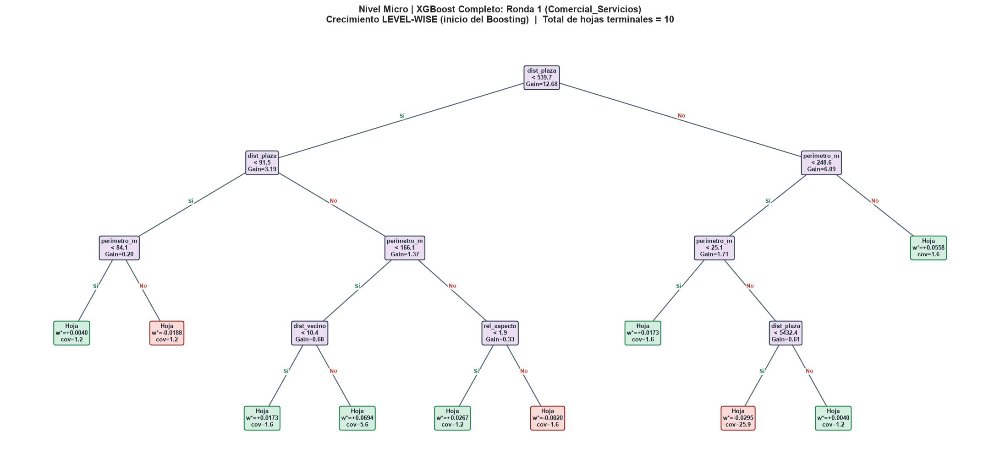

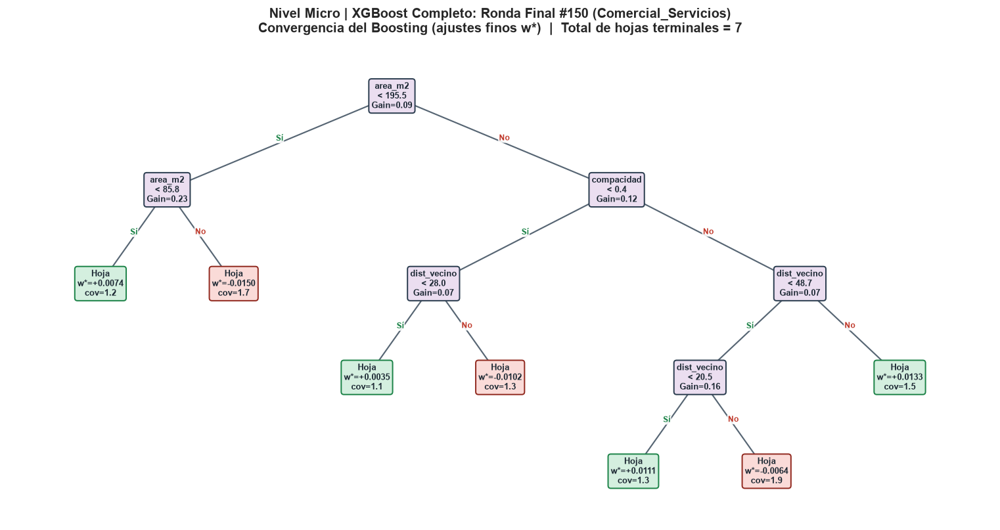

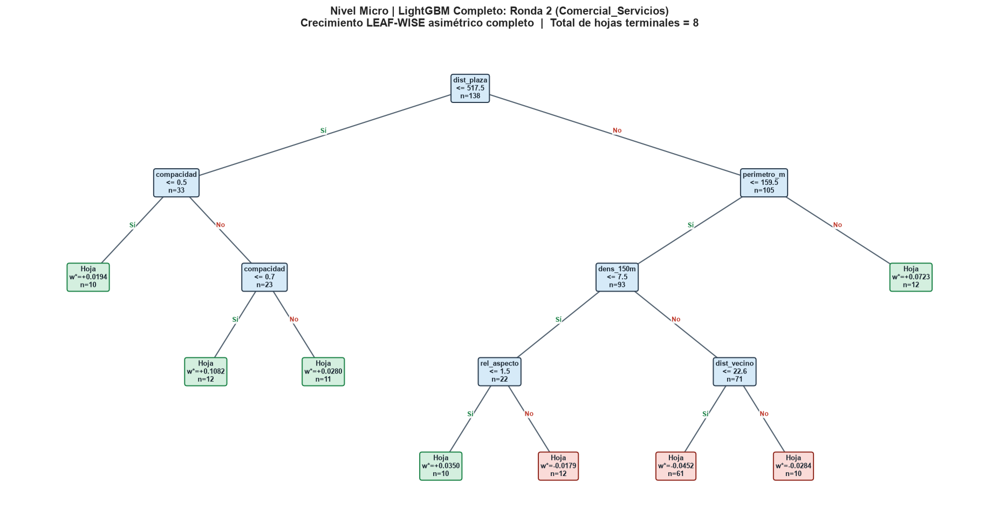

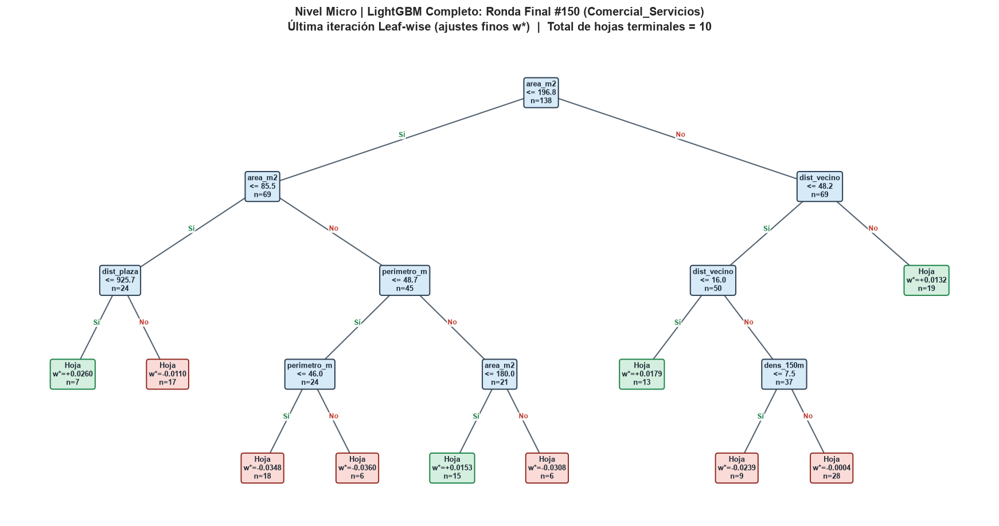

In [9]:
# Helper reutilizable de renderizado completo de árboles de Boosting (Matplotlib puro, sin Graphviz)
def acortar_var(s):
    for a, b in [
        ('dist_plaza_armas_m', 'dist_plaza'), ('dist_vecino_cercano_m', 'dist_vecino'),
        ('dist_via_cercana_m', 'dist_via'), ('pois_entorno_300m', 'pois_300m'),
        ('densidad_edificios_150m', 'dens_150m'), ('relacion_aspecto', 'rel_aspecto'),
        ('dist_lago_agua_m', 'dist_lago'), ('dist_quebrada_rio_m', 'dist_rio'),
        ('dist_via_principal_m', 'dist_via_art'), ('dist_poi_cercano_m', 'dist_poi'),
        ('dist_transporte_m', 'dist_transp'), ('longitud_vias_m', 'long_vias'),
        ('pct_vias_arteriales', 'pct_art'), ('pct_vias_rurales_peat', 'pct_rural'),
        ('pct_area_construida', 'pct_constr')
    ]:
        s = str(s).replace(a, b)
    return s

def extraer_xgb(xgb_model, tree_idx):
    df_t = xgb_model.get_booster().trees_to_dataframe()
    sub = df_t[df_t['Tree'] == tree_idx].set_index('ID')
    def build(nid):
        row = sub.loc[nid]
        if row['Feature'] == 'Leaf':
            val = float(row['Gain'])
            return {'label': f"Hoja\nw*={val:+.4f}\ncov={row['Cover']:.1f}", 'is_leaf': True, 'val': val, 'left': None, 'right': None}
        return {'label': f"{acortar_var(row['Feature'])}\n< {float(row['Split']):.1f}\nGain={float(row['Gain']):.2f}",
                'is_leaf': False, 'val': 0.0, 'left': build(row['Yes']), 'right': build(row['No'])}
    return build(f"{tree_idx}-0")

def extraer_lgbm(lgbm_model, tree_idx):
    df_t = lgbm_model.booster_.trees_to_dataframe()
    sub = df_t[df_t['tree_index'] == tree_idx].set_index('node_index')
    root_id = sub[sub['node_depth'] == 1].index[0]
    def build(nid):
        row = sub.loc[nid]
        if pd.isna(row['split_feature']):
            val = float(row['value'])
            return {'label': f"Hoja\nw*={val:+.4f}\nn={int(row['count'])}", 'is_leaf': True, 'val': val, 'left': None, 'right': None}
        return {'label': f"{acortar_var(row['split_feature'])}\n<= {float(row['threshold']):.1f}\nn={int(row['count'])}",
                'is_leaf': False, 'val': 0.0, 'left': build(row['left_child']), 'right': build(row['right_child'])}
    return build(root_id)

def dibujar_arbol_boosting_completo(root, titulo, subtitulo, color_nodo, fname, figsize=(19, 9), fontsize=8.2):
    coords, leaf_cnt, max_d = {}, [0], [0]
    def pos(node, depth):
        max_d[0] = max(max_d[0], depth)
        if node['left'] is None and node['right'] is None:
            x = leaf_cnt[0]; leaf_cnt[0] += 1; coords[id(node)] = (x, -depth); return x
        x = (pos(node['left'], depth + 1) + pos(node['right'], depth + 1)) / 2.0
        coords[id(node)] = (x, -depth); return x
    pos(root, 0)
    fig, ax = plt.subplots(figsize=figsize)
    def draw(node):
        x, y = coords[id(node)]
        for side, ch, elbl in [('L', node['left'], 'Sí'), ('R', node['right'], 'No')]:
            if ch is not None:
                cx, cy = coords[id(ch)]
                ax.plot([x, cx], [y, cy], color='#566573', linewidth=1.4, zorder=1)
                ax.text((x+cx)/2, (y+cy)/2 + 0.05, elbl, fontsize=max(fontsize-0.5, 6.5), fontweight='bold',
                        color='#1e8449' if side == 'L' else '#c0392b', ha='center', va='center',
                        bbox=dict(boxstyle='round,pad=0.12', facecolor='white', edgecolor='none', alpha=0.88))
                draw(ch)
        fc = ('#d4efdf' if node['val'] >= 0 else '#fadbd8') if node['is_leaf'] else color_nodo
        ec = ('#1e8449' if node['val'] >= 0 else '#922b21') if node['is_leaf'] else '#2c3e50'
        ax.text(x, y, node['label'], ha='center', va='center', fontsize=fontsize, fontweight='bold', color='#1c2833',
                bbox=dict(boxstyle='round,pad=0.33', facecolor=fc, edgecolor=ec, linewidth=1.3), zorder=3)
    draw(root)
    ax.set_xlim(-0.7, leaf_cnt[0] - 0.3); ax.set_ylim(-max_d[0] - 0.55, 0.55); ax.axis('off')
    ax.set_title(f"{titulo}\n{subtitulo}  |  Total de hojas terminales = {leaf_cnt[0]}", fontsize=13, fontweight='bold', pad=12)
    plt.tight_layout()
    plt.savefig(DIR_FIGURES / fname, bbox_inches='tight', dpi=250)
    plt.show()

# 1. DecisionTree Gini y Entropía completos
for key, col_t, fname in [
    ('DecisionTree (Gini)', '#d35400', '02_arbol_gini_completo.png'),
    ('DecisionTree (Entropía)', '#1f618d', '02_arbol_entropia_completo.png')
]:
    est = modelos_mi_fit[key]
    fig, ax = plt.subplots(figsize=(22, 10))
    plot_tree(est, feature_names=FEATURES_MICRO, class_names=clases_mi, filled=True, rounded=True, fontsize=9, ax=ax)
    ax.set_title(f"Nivel Micro | {key} Completo | Profundidad = {est.get_depth()} | Hojas = {est.get_n_leaves()}",
                 fontsize=14, fontweight='bold', color=col_t, pad=12)
    plt.tight_layout(); plt.savefig(DIR_FIGURES / fname, bbox_inches='tight'); plt.show()

# 2. Random Forest: Árbol #1 y Árbol #200 completos
for idx_t, fname, sub in [(0, '02_arbol_rf_001_completo.png', 'Árbol #1 de 200'), (199, '02_arbol_rf_200_completo.png', 'Último Árbol #200 de 200')]:
    est = modelos_mi_fit['Random Forest'].estimators_[idx_t]
    fig, ax = plt.subplots(figsize=(30, 14))
    plot_tree(est, feature_names=FEATURES_MICRO, class_names=clases_mi, filled=True, rounded=True, fontsize=7, ax=ax)
    ax.set_title(f"Nivel Micro | Random Forest ({sub}) Completo | Profundidad = {est.get_depth()} | Hojas = {est.get_n_leaves()}",
                 fontsize=15, fontweight='bold', color='#1e8449', pad=12)
    plt.tight_layout(); plt.savefig(DIR_FIGURES / fname, bbox_inches='tight'); plt.show()

# 3 y 4. XGBoost (Ronda 1 y #150) y LightGBM (Ronda 2 y #150) completos
dibujar_arbol_boosting_completo(extraer_xgb(modelos_mi_fit['XGBoost'], 0), "Nivel Micro | XGBoost Completo: Ronda 1 (Comercial_Servicios)",
                                "Crecimiento LEVEL-WISE (inicio del Boosting)", '#ebdef0', "02_arbol_xgboost_ronda1_completo.png", (20, 9.5))
dibujar_arbol_boosting_completo(extraer_xgb(modelos_mi_fit['XGBoost'], 447), "Nivel Micro | XGBoost Completo: Ronda Final #150 (Comercial_Servicios)",
                                "Convergencia del Boosting (ajustes finos w*)", '#ebdef0', "02_arbol_xgboost_ronda150_completo.png", (14, 7.5))
dibujar_arbol_boosting_completo(extraer_lgbm(modelos_mi_fit['LightGBM'], 3), "Nivel Micro | LightGBM Completo: Ronda 2 (Comercial_Servicios)",
                                "Crecimiento LEAF-WISE asimétrico completo", '#d6eaf8', "02_arbol_lightgbm_ronda2_completo.png", (17, 9))
dibujar_arbol_boosting_completo(extraer_lgbm(modelos_mi_fit['LightGBM'], 447), "Nivel Micro | LightGBM Completo: Ronda Final #150 (Comercial_Servicios)",
                                "Última iteración Leaf-wise (ajustes finos w*)", '#d6eaf8', "02_arbol_lightgbm_ronda150_completo.png", (16, 8.5))

## 2.5. Matrices de Confusión, Feature Importance, Imputación y Mapa Micro

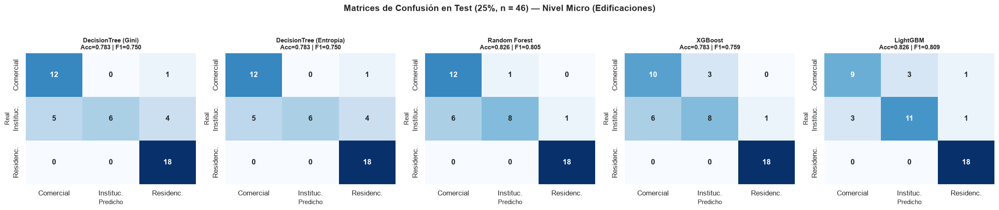

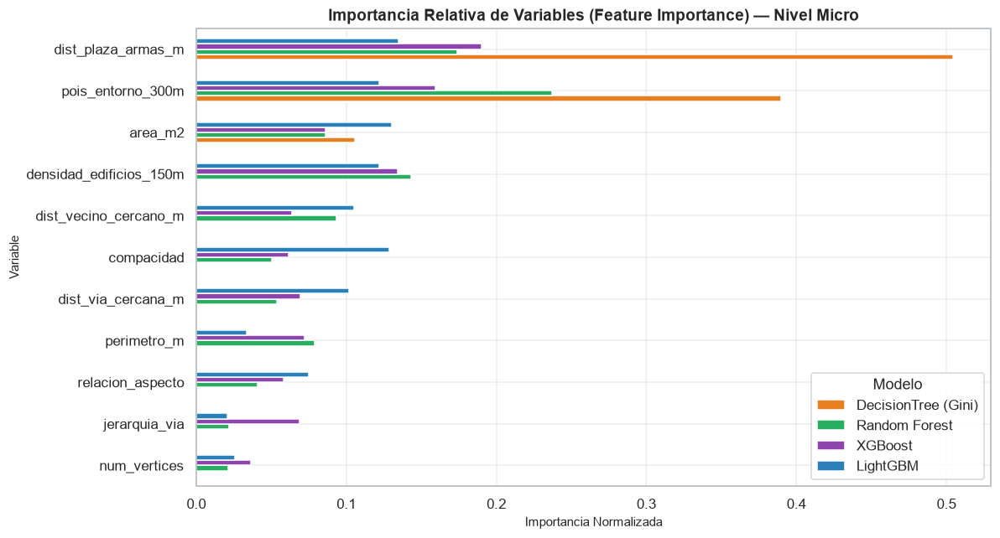

Modelo ganador Nivel Micro: XGBoost (CV-5 F1 = 0.7275)


origen_etiqueta,Predicho (ML),Verificado (OSM),All
clase_final,,,
Comercial_Servicios,117,51,168
Institucional,221,60,281
Residencial,130,73,203
All,468,184,652


In [10]:
# Matrices de Confusión (Nivel Micro — Test n=46)
fig, axes = plt.subplots(1, 5, figsize=(22, 4.4))
for ax, (nombre, yp) in zip(axes, preds_mi_test.items()):
    cm = confusion_matrix(y_mi_test, yp)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={'size': 12, 'weight': 'bold'},
                xticklabels=['Comercial', 'Instituc.', 'Residenc.'], yticklabels=['Comercial', 'Instituc.', 'Residenc.'], ax=ax)
    ax.set_title(f"{nombre}\nAcc={accuracy_score(y_mi_test, yp):.3f} | F1={f1_score(y_mi_test, yp, average='macro'):.3f}", fontsize=10, fontweight='bold')
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.suptitle("Matrices de Confusión en Test (25%, n = 46) — Nivel Micro (Edificaciones)", fontsize=13.5, fontweight='bold', y=1.04)
plt.tight_layout(); plt.savefig(DIR_FIGURES / "02_matrices_confusion_micro.png", bbox_inches='tight'); plt.show()

# Feature Importance (Nivel Micro)
imp_mi = pd.DataFrame(index=FEATURES_MICRO)
for n in ['DecisionTree (Gini)', 'Random Forest', 'XGBoost', 'LightGBM']:
    v = modelos_mi_fit[n].feature_importances_
    imp_mi[n] = v / (v.sum() + 1e-9)
imp_mi['Prom'] = imp_mi.mean(axis=1)
imp_mi = imp_mi.sort_values('Prom', ascending=True)
imp_mi.drop(columns=['Prom']).plot(kind='barh', figsize=(11, 6.0), color=['#e67e22', '#27ae60', '#8e44ad', '#2980b9'], edgecolor='white')
plt.title("Importancia Relativa de Variables (Feature Importance) — Nivel Micro", fontsize=12.5, fontweight='bold')
plt.xlabel("Importancia Normalizada"); plt.ylabel("Variable"); plt.legend(title="Modelo", loc="lower right")
plt.tight_layout(); plt.savefig(DIR_FIGURES / "02_feature_importance_micro.png", bbox_inches='tight'); plt.show()

# Reentrenamiento con 100% de las 184 verificadas e imputación de las 468 faltantes
nombre_ganador_mi = df_resultados_micro.iloc[0]['Modelo']
cv_f1_ganador_mi = df_resultados_micro.iloc[0]['CV-5 F1 (Macro)']
modelo_ganador_mi = crear_modelos_micro()[nombre_ganador_mi]
modelo_ganador_mi.fit(X_mi, y_mi)

mask_unlab_mi = b_utm['clase_uso'].isnull()
preds_unlab_mi = le_mi.inverse_transform(modelo_ganador_mi.predict(b_utm.loc[mask_unlab_mi, FEATURES_MICRO]))
b_utm['origen_etiqueta'] = np.where(mask_unlab_mi, 'Predicho (ML)', 'Verificado (OSM)')
b_utm['clase_final'] = b_utm['clase_uso'].copy()
b_utm.loc[mask_unlab_mi, 'clase_final'] = preds_unlab_mi

print(f"Modelo ganador Nivel Micro: {nombre_ganador_mi} (CV-5 F1 = {cv_f1_ganador_mi:.4f})")
display(pd.crosstab(b_utm['clase_final'], b_utm['origen_etiqueta'], margins=True))

b_final_wgs84 = b_utm.to_crs(CRS_GEO)
b_final_wgs84.to_file(DIR_DATA_PUNO / "puno_buildings_clasificados.geojson", driver="GeoJSON")

In [11]:
# Mapa Interactivo Folium — Nivel Micro (Edificaciones Clasificadas)
colores_mi_map = {'Residencial': '#2e86de', 'Comercial_Servicios': '#f39c12', 'Institucional': '#8e44ad'}
m_micro = folium.Map(location=[-15.8402, -70.0280], zoom_start=15, tiles="OpenStreetMap")
Fullscreen(position='topright').add_to(m_micro)
MiniMap(toggle_display=True, minimized=True).add_to(m_micro)
folium.GeoJson(puno_distrito, name="Límite Distrito de Puno",
               style_function=lambda x: {'fillColor': 'none', 'color': '#2c3e50', 'weight': 2.2, 'dashArray': '6, 4'}).add_to(m_micro)

b_viz = b_final_wgs84[['name', 'clase_final', 'origen_etiqueta', 'area_m2', 'dist_plaza_armas_m', 'pois_entorno_300m', 'densidad_edificios_150m', 'geometry']].copy()
b_viz['name'] = b_viz['name'].fillna('Edificación sin nombre')
b_viz['area_m2'] = b_viz['area_m2'].round(1)
b_viz['dist_plaza_armas_m'] = b_viz['dist_plaza_armas_m'].round(0).astype(int)
b_viz['pois_entorno_300m'] = b_viz['pois_entorno_300m'].astype(int)
b_viz['densidad_edificios_150m'] = b_viz['densidad_edificios_150m'].astype(int)

for clase, color in colores_mi_map.items():
    sub = b_viz[b_viz['clase_final'] == clase]
    fg = folium.FeatureGroup(name=f"{clase} ({len(sub)})", show=True)
    folium.GeoJson(
        sub,
        style_function=lambda feat, c=color: {
            'fillColor': c,
            'color': '#111111' if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else c,
            'weight': 1.8 if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else 1.0,
            'dashArray': None if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else '3, 3',
            'fillOpacity': 0.88 if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else 0.68
        },
        highlight_function=lambda feat: {'weight': 3.0, 'color': '#e74c3c', 'fillOpacity': 0.95},
        tooltip=folium.GeoJsonTooltip(fields=['name', 'clase_final', 'origen_etiqueta', 'area_m2'],
                                      aliases=['Edificio:', 'Clase:', 'Origen:', 'Área (m²):'], localize=True),
        popup=folium.GeoJsonPopup(fields=['name', 'clase_final', 'origen_etiqueta', 'area_m2', 'dist_plaza_armas_m', 'pois_entorno_300m'],
                                  aliases=['Edificio:', 'Categoría:', 'Origen:', 'Área (m²):', 'Dist. Plaza (m):', 'POIs 300m:'], localize=True)
    ).add_to(fg)
    fg.add_to(m_micro)

folium.Marker([-15.8402, -70.0280], tooltip="Plaza de Armas de Puno", icon=folium.Icon(color='red', icon='star')).add_to(m_micro)
folium.LayerControl(collapsed=False).add_to(m_micro)
m_micro.save(DIR_DATA_PUNO / "mapa_micro_edificaciones.html")
m_micro

---
# PARTE 3: Nivel Macro — Zonificación Urbana en Grilla de $250\text{ m} \times 250\text{ m}$

## 3.1. Generación de la Grilla Espacial, Etiquetado Verificable e Ingeniería de 17 Variables ($X$)
Dividimos Puno en celdas regulares de **$250\text{ m} \times 250\text{ m}$ ($6.25\text{ ha}$)**, seleccionamos las **`2,100` celdas activas** (`1,009` verificadas en 4 zonas desde `puno_landuse` y `puno_pois_a` + `1,091` sin etiqueta) y construimos **17 variables predictoras ($X$)** integrando las predicciones del **Nivel Micro (Parte 2)**, la red vial, el transporte, los POIs (`cKDTree`) y la distancia al Lago Titicaca y quebradas.

In [12]:
CELL_SIZE = 250
CELL_AREA = CELL_SIZE * CELL_SIZE
puno_geom_utm = puno_utm.geometry.iloc[0]
minx, miny, maxx, maxy = puno_utm.total_bounds

celdas = [box(x, y, x + CELL_SIZE, y + CELL_SIZE) for x in np.arange(minx, maxx, CELL_SIZE) for y in np.arange(miny, maxy, CELL_SIZE)]
grid = gpd.GeoDataFrame({'cell_id': range(len(celdas)), 'geometry': celdas}, crs=CRS_METRICO)
grid = grid[grid.intersects(puno_geom_utm)].reset_index(drop=True)
grid['cell_id'] = grid.index

def celdas_que_intersectan(capa_gdf, fclasses=None):
    sub = capa_gdf if fclasses is None else capa_gdf[capa_gdf['fclass'].isin(fclasses)]
    return set() if len(sub) == 0 else set(gpd.sjoin(grid[['cell_id', 'geometry']], sub[['geometry']], predicate='intersects')['cell_id'])

c_equip_prod = (
    celdas_que_intersectan(lu_utm, ['industrial', 'retail', 'military', 'landfill', 'quarry']) |
    celdas_que_intersectan(pa_utm, ['school', 'university', 'hospital', 'marketplace', 'college', 'stadium', 'police'])
)
c_verdes = (
    celdas_que_intersectan(lu_utm, ['park', 'recreation_ground', 'grass', 'cemetery']) |
    celdas_que_intersectan(pa_utm, ['park', 'pitch', 'playground', 'graveyard'])
)
c_rural = celdas_que_intersectan(lu_utm, ['farmland', 'scrub', 'forest', 'meadow', 'allotments'])
c_res = celdas_que_intersectan(lu_utm, ['residential'])

c_activas = c_equip_prod | c_verdes | c_rural | c_res | celdas_que_intersectan(rd_utm) | celdas_que_intersectan(b_utm) | celdas_que_intersectan(p_utm)
grid_activas = grid[grid['cell_id'].isin(c_activas)].copy().reset_index(drop=True)

def asignar_zona_macro(cid):
    if cid in c_equip_prod: return 'Equipamiento_Productivo'
    if cid in c_verdes: return 'Areas_Verdes_Recreacion'
    if cid in c_rural: return 'Rural_Agricola_Natural'
    if cid in c_res: return 'Urbano_Residencial'
    return np.nan

grid_activas['zona_macro'] = grid_activas['cell_id'].apply(asignar_zona_macro)

# 1. Agregación Nivel Micro
b_cent_m = b_utm[['clase_final', 'area_m2', 'geometry']].copy()
b_cent_m['geometry'] = b_cent_m.geometry.centroid
j_build = gpd.sjoin(grid_activas[['cell_id', 'geometry']], b_cent_m, how='left', predicate='contains').reset_index(drop=True)
agg_b = j_build.groupby('cell_id').agg(num_edificios=('area_m2', 'count'), area_construida_m2=('area_m2', 'sum')).fillna(0)
agg_b['pct_area_construida'] = (agg_b['area_construida_m2'] / CELL_AREA) * 100.0
ct_micro = pd.crosstab(j_build['cell_id'], j_build['clase_final'])
for col, ncol in [('Residencial', 'edificios_residenciales'), ('Comercial_Servicios', 'edificios_comerciales'), ('Institucional', 'edificios_institucionales')]:
    grid_activas[ncol] = grid_activas['cell_id'].map(ct_micro[col] if col in ct_micro else pd.Series()).fillna(0)
grid_activas['num_edificios'] = grid_activas['cell_id'].map(agg_b['num_edificios']).fillna(0)
grid_activas['pct_area_construida'] = grid_activas['cell_id'].map(agg_b['pct_area_construida']).fillna(0)

# 2. Morfología vial
vias_rur_set = {'track', 'path', 'footway', 'steps', 'pedestrian'}
roads_clip = gpd.overlay(rd_utm[['fclass', 'geometry']], grid_activas[['cell_id', 'geometry']], how='intersection', keep_geom_type=False)
roads_clip['len_m'] = roads_clip.geometry.length
roads_clip['len_arterial'] = np.where(roads_clip['fclass'].isin(vias_art_set), roads_clip['len_m'], 0.0)
roads_clip['len_rural'] = np.where(roads_clip['fclass'].isin(vias_rur_set), roads_clip['len_m'], 0.0)
agg_roads = roads_clip.groupby('cell_id').agg(longitud_vias_m=('len_m', 'sum'), num_tramos_via=('len_m', 'count'), len_arterial=('len_arterial', 'sum'), len_rural=('len_rural', 'sum'))
agg_roads['pct_vias_arteriales'] = agg_roads['len_arterial'] / (agg_roads['longitud_vias_m'] + 1e-6)
agg_roads['pct_vias_rurales_peat'] = agg_roads['len_rural'] / (agg_roads['longitud_vias_m'] + 1e-6)
for col in ['longitud_vias_m', 'num_tramos_via', 'pct_vias_arteriales', 'pct_vias_rurales_peat']:
    grid_activas[col] = grid_activas['cell_id'].map(agg_roads[col]).fillna(0)

centroides_grid = gpd.GeoDataFrame({'cell_id': grid_activas['cell_id'], 'geometry': grid_activas.geometry.centroid}, crs=CRS_METRICO)
near_art = gpd.sjoin_nearest(centroides_grid, rd_utm[rd_utm['fclass'].isin(vias_art_set)][['geometry']], how='left', distance_col='dist_via_principal_m').drop_duplicates('cell_id')
grid_activas['dist_via_principal_m'] = grid_activas['cell_id'].map(near_art.set_index('cell_id')['dist_via_principal_m'])

# 3. POIs y Transporte (cKDTree)
coords_grid = np.column_stack([centroides_grid.geometry.x, centroides_grid.geometry.y])
j_pois = gpd.sjoin(grid_activas[['cell_id', 'geometry']], p_utm[['geometry']], how='left', predicate='contains').reset_index(drop=True)
grid_activas['num_pois_celda'] = grid_activas['cell_id'].map(j_pois.groupby('cell_id')['index_right'].count()).fillna(0)
dist_poi, _ = tree_pois.query(coords_grid, k=1)
grid_activas['dist_poi_cercano_m'] = dist_poi
grid_activas['num_pois_500m'] = [len(idx) for idx in tree_pois.query_ball_point(coords_grid, r=500.0)]
tree_transp = cKDTree(np.column_stack([tr_utm.geometry.x, tr_utm.geometry.y]))
grid_activas['dist_transporte_m'] = tree_transp.query(coords_grid, k=1)[0]

# 4. Hidrografía y Plaza de Armas
grid_activas['dist_plaza_armas_m'] = centroides_grid.geometry.distance(plaza_armas_utm)
grid_activas['dist_lago_agua_m'] = centroides_grid.geometry.distance(wa_utm.geometry.union_all())
grid_activas['dist_quebrada_rio_m'] = centroides_grid.geometry.distance(ww_utm.geometry.union_all())

FEATURES_MACRO = [
    'num_edificios', 'pct_area_construida',
    'edificios_residenciales', 'edificios_comerciales', 'edificios_institucionales',
    'longitud_vias_m', 'num_tramos_via', 'pct_vias_arteriales', 'pct_vias_rurales_peat', 'dist_via_principal_m',
    'num_pois_celda', 'num_pois_500m', 'dist_poi_cercano_m', 'dist_transporte_m',
    'dist_plaza_armas_m', 'dist_lago_agua_m', 'dist_quebrada_rio_m'
]
df_macro = grid_activas[['cell_id', 'zona_macro'] + FEATURES_MACRO].copy()
df_macro.to_csv(DIR_DATA_PUNO / "dataset_macro_zonificacion.csv", index=False)

print(f"Grilla Macro generada: {len(grid_activas):,} celdas activas | Verificadas: {df_macro['zona_macro'].notna().sum():,} | A predecir: {df_macro['zona_macro'].isna().sum():,}")
muestra_ma = (
    df_macro.dropna(subset=['zona_macro']).groupby('zona_macro', group_keys=False).head(2)
    [['cell_id', 'num_edificios', 'longitud_vias_m', 'pct_vias_arteriales', 'num_pois_500m', 'dist_plaza_armas_m', 'dist_lago_agua_m', 'zona_macro']].copy()
)
display(
    muestra_ma.style
    .set_caption("Ejemplos reales — Dataset Nivel Macro (columna resaltada = Variable Objetivo y)")
    .set_properties(subset=['zona_macro'], **{'background-color': '#d6eaf8', 'color': '#1b4f72', 'font-weight': 'bold'})
    .format({'longitud_vias_m': '{:.1f}', 'pct_vias_arteriales': '{:.2f}', 'dist_plaza_armas_m': '{:.1f}', 'dist_lago_agua_m': '{:.1f}'})
)

Grilla Macro generada: 2,100 celdas activas | Verificadas: 1,009 | A predecir: 1,091


,cell_id,num_edificios,longitud_vias_m,pct_vias_arteriales,num_pois_500m,dist_plaza_armas_m,dist_lago_agua_m,zona_macro
249,3223,0,308.2,0.87,0,6144.5,6961.4,Urbano_Residencial
274,3322,0,30.4,0.00,0,5653.9,6618.9,Urbano_Residencial
390,3792,0,0.0,0.00,0,7622.0,7972.1,Equipamiento_Productivo
391,3793,0,0.0,0.00,0,7417.4,7808.8,Equipamiento_Productivo
537,4296,0,0.0,0.00,0,3519.2,4211.8,Rural_Agricola_Natural
571,4385,0,504.9,0.00,1,3303.4,3967.6,Rural_Agricola_Natural
602,4464,0,191.4,0.00,0,2624.0,3837.0,Areas_Verdes_Recreacion
611,4474,0,1636.6,0.00,5,3238.5,3790.9,Areas_Verdes_Recreacion


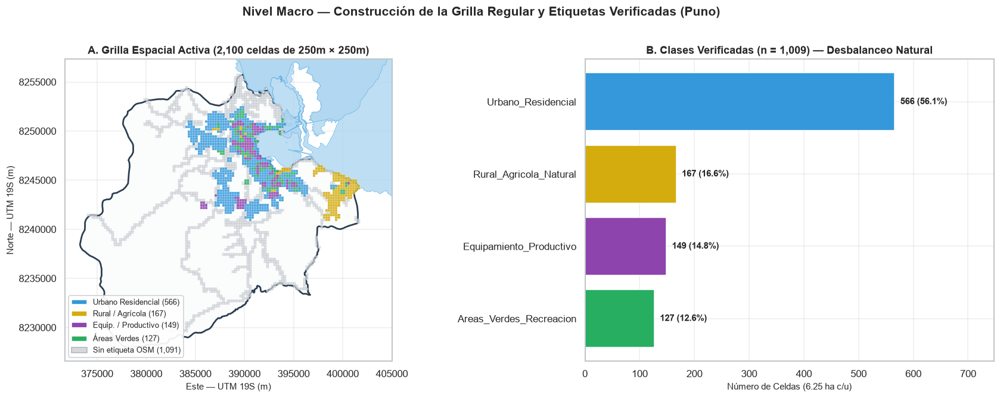

In [13]:
# Lámina de la Grilla Espacial 250m×250m y Desbalanceo Natural
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.0), gridspec_kw={'width_ratios': [1.15, 1]})
colores_zonas_map = {'Urbano_Residencial': '#3498db', 'Rural_Agricola_Natural': '#d4ac0d', 'Equipamiento_Productivo': '#8e44ad', 'Areas_Verdes_Recreacion': '#27ae60'}

puno_utm.plot(ax=ax1, color='#fbfcfc', edgecolor='#2c3e50', linewidth=1.8, zorder=1)
wa_utm.plot(ax=ax1, color='#aed6f1', edgecolor='#5dade2', linewidth=0.5, alpha=0.8, zorder=2)
grid_activas[grid_activas['zona_macro'].isna()].plot(ax=ax1, color='#d5d8dc', edgecolor='#aeb6bf', linewidth=0.25, alpha=0.7, zorder=3)
for z_name, z_col in colores_zonas_map.items():
    grid_activas[grid_activas['zona_macro'] == z_name].plot(ax=ax1, color=z_col, edgecolor='white', linewidth=0.2, alpha=0.88, zorder=4)
ax1.set_xlim(bminx - 1500, bmaxx + 3500); ax1.set_ylim(bminy - 1500, bmaxy + 1500)
ax1.set_title("A. Grilla Espacial Activa (2,100 celdas de 250m × 250m)")
ax1.set_xlabel("Este — UTM 19S (m)"); ax1.set_ylabel("Norte — UTM 19S (m)"); ax1.ticklabel_format(style='plain', axis='both')
ax1.legend(handles=[
    mpatches.Patch(facecolor='#3498db', label='Urbano Residencial (566)'),
    mpatches.Patch(facecolor='#d4ac0d', label='Rural / Agrícola (167)'),
    mpatches.Patch(facecolor='#8e44ad', label='Equip. / Productivo (149)'),
    mpatches.Patch(facecolor='#27ae60', label='Áreas Verdes (127)'),
    mpatches.Patch(facecolor='#d5d8dc', edgecolor='#aeb6bf', label='Sin etiqueta OSM (1,091)')
], loc='lower left', fontsize=8.3, frameon=True, facecolor='white', framealpha=0.93)

orden_z = ['Urbano_Residencial', 'Rural_Agricola_Natural', 'Equipamiento_Productivo', 'Areas_Verdes_Recreacion']
cnt_z = grid_activas['zona_macro'].value_counts().reindex(orden_z)
bars = ax2.barh(orden_z[::-1], cnt_z.values[::-1], color=[colores_zonas_map[z] for z in orden_z[::-1]], edgecolor='white')
ax2.set_title("B. Clases Verificadas (n = 1,009) — Desbalanceo Natural")
ax2.set_xlabel("Número de Celdas (6.25 ha c/u)"); ax2.set_xlim(0, cnt_z.max() * 1.32)
for b in bars:
    w = int(b.get_width())
    ax2.annotate(f"{w} ({w/cnt_z.sum()*100:.1f}%)", (w + 10, b.get_y() + b.get_height()/2), va='center', fontsize=9.8, fontweight='bold')
plt.suptitle("Nivel Macro — Construcción de la Grilla Regular y Etiquetas Verificadas (Puno)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout(); plt.savefig(DIR_FIGURES / "03_grilla_espacial_macro.png", bbox_inches='tight'); plt.show()

## 3.2. Validación (`75/25 + 5-Fold CV sobre 75% Train`), Balanceo Matemático ($w_k = \frac{N}{K \cdot N_k}$) y Entrenamiento
Para compensar que `Urbano_Residencial` abarca el `56.1%` frente a `12.6%` de `Áreas Verdes`, aplicamos pesos balanceados inversamente proporcionales a la frecuencia de clase (`class_weight='balanced'` / `compute_sample_weight('balanced')`) y evaluamos con **F1-Score Macro** y **Balanced Accuracy**.

In [14]:
df_ma_lab = df_macro.dropna(subset=['zona_macro']).copy().reset_index(drop=True)
X_ma = df_ma_lab[FEATURES_MACRO].copy()
le_ma = LabelEncoder()
y_ma = le_ma.fit_transform(df_ma_lab['zona_macro'])
clases_ma = list(le_ma.classes_)

X_ma_train, X_ma_test, y_ma_train, y_ma_test = train_test_split(
    X_ma, y_ma, test_size=0.25, random_state=42, stratify=y_ma
)

# Búsqueda de profundidad óptima Gini vs Entropía (Macro)
prof_ma = range(2, 13)
sc_g_ma, sc_e_ma = [], []
for d in prof_ma:
    fg, fe = [], []
    for ti, vi in cv.split(X_ma_train, y_ma_train):
        dg = DecisionTreeClassifier(criterion='gini', max_depth=d, min_samples_leaf=5, class_weight='balanced', random_state=42).fit(X_ma_train.iloc[ti], y_ma_train[ti])
        de = DecisionTreeClassifier(criterion='entropy', max_depth=d, min_samples_leaf=5, class_weight='balanced', random_state=42).fit(X_ma_train.iloc[ti], y_ma_train[ti])
        fg.append(f1_score(y_ma_train[vi], dg.predict(X_ma_train.iloc[vi]), average='macro'))
        fe.append(f1_score(y_ma_train[vi], de.predict(X_ma_train.iloc[vi]), average='macro'))
    sc_g_ma.append(np.mean(fg)); sc_e_ma.append(np.mean(fe))
mejor_d_g_ma = list(prof_ma)[int(np.argmax(sc_g_ma))]
mejor_d_e_ma = list(prof_ma)[int(np.argmax(sc_e_ma))]

def crear_modelos_macro():
    return {
        'DecisionTree (Gini)': DecisionTreeClassifier(criterion='gini', max_depth=mejor_d_g_ma, min_samples_leaf=5, class_weight='balanced', random_state=42),
        'DecisionTree (Entropía)': DecisionTreeClassifier(criterion='entropy', max_depth=mejor_d_e_ma, min_samples_leaf=5, class_weight='balanced', random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=250, max_depth=12, min_samples_leaf=3, class_weight='balanced', random_state=42, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42),
        'LightGBM': LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.05, num_leaves=25, min_child_samples=15, class_weight='balanced', random_state=42, verbose=-1)
    }

res_ma_list, preds_ma_test, modelos_ma_fit = [], {}, {}
for nombre, modelo in crear_modelos_macro().items():
    cv_accs, cv_f1s = [], []
    for ti, vi in cv.split(X_ma_train, y_ma_train):
        m_cv = crear_modelos_macro()[nombre]
        if nombre == 'XGBoost':
            m_cv.fit(X_ma_train.iloc[ti], y_ma_train[ti], sample_weight=compute_sample_weight('balanced', y_ma_train[ti]))
        else:
            m_cv.fit(X_ma_train.iloc[ti], y_ma_train[ti])
        pv = m_cv.predict(X_ma_train.iloc[vi])
        cv_accs.append(accuracy_score(y_ma_train[vi], pv)); cv_f1s.append(f1_score(y_ma_train[vi], pv, average='macro'))

    t0 = time.perf_counter()
    if nombre == 'XGBoost':
        modelo.fit(X_ma_train, y_ma_train, sample_weight=compute_sample_weight('balanced', y_ma_train))
    else:
        modelo.fit(X_ma_train, y_ma_train)
    t_ms = (time.perf_counter() - t0) * 1000
    yp = modelo.predict(X_ma_test)
    preds_ma_test[nombre] = yp
    modelos_ma_fit[nombre] = modelo
    res_ma_list.append({
        'Modelo': nombre,
        'Test Accuracy': accuracy_score(y_ma_test, yp),
        'Test Balanced Acc': balanced_accuracy_score(y_ma_test, yp),
        'Test Precision (Macro)': precision_score(y_ma_test, yp, average='macro', zero_division=0),
        'Test Recall (Macro)': recall_score(y_ma_test, yp, average='macro', zero_division=0),
        'Test F1 (Macro)': f1_score(y_ma_test, yp, average='macro', zero_division=0),
        'CV-5 Accuracy': np.mean(cv_accs),
        'CV-5 F1 (Macro)': np.mean(cv_f1s),
        'Tiempo Train (ms)': t_ms
    })

df_resultados_macro = pd.DataFrame(res_ma_list).sort_values(by='CV-5 F1 (Macro)', ascending=False)
df_resultados_macro.to_csv(DIR_DATA_PUNO / "resultados_macro_modelos.csv", index=False)
print(f"Profundidad óptima Macro -> Gini: {mejor_d_g_ma} | Entropía: {mejor_d_e_ma}")
display(df_resultados_macro.round(4))

Profundidad óptima Macro -> Gini: 6 | Entropía: 8


,Modelo,Test Accuracy,Test Balanced Acc,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro),CV-5 Accuracy,CV-5 F1 (Macro),Tiempo Train (ms)
3,XGBoost,0.7787,0.7286,0.7095,0.7286,0.7133,0.7778,0.7029,578.6509
4,LightGBM,0.7787,0.7123,0.6966,0.7123,0.7040,0.7778,0.6991,332.9422
2,Random Forest,0.7549,0.7049,0.6782,0.7049,0.6854,0.7685,0.6969,700.9836
0,DecisionTree (Gini),0.6838,0.6293,0.6217,0.6293,0.6161,0.7169,0.6655,5.1912
1,DecisionTree (Entropía),0.6640,0.6642,0.6195,0.6642,0.6179,0.7037,0.6393,9.1822


## 3.3. Visualización Completa de los Árboles en Nivel Macro (Sin Recortes `(...)`)

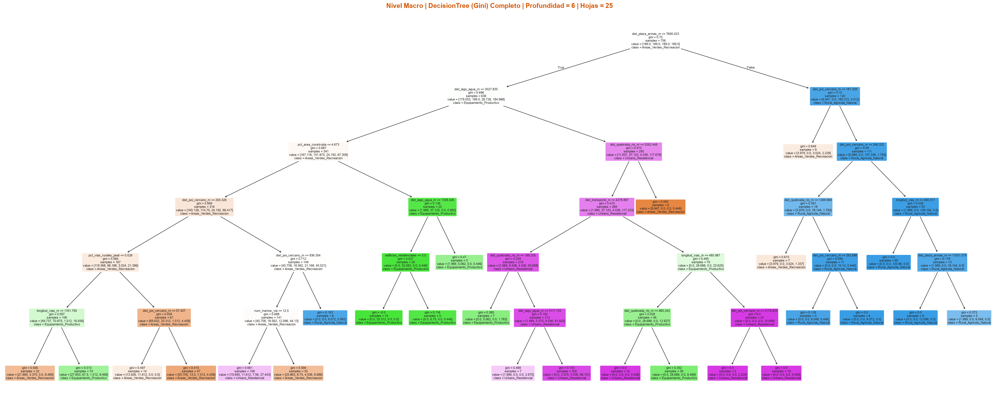

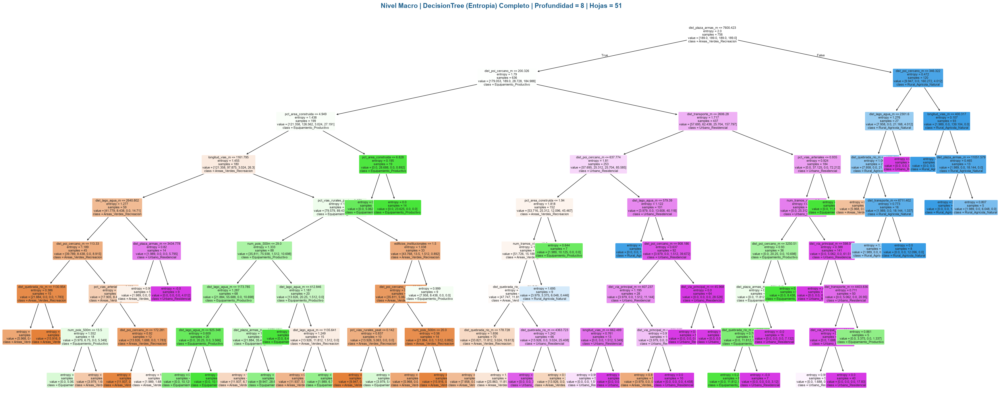

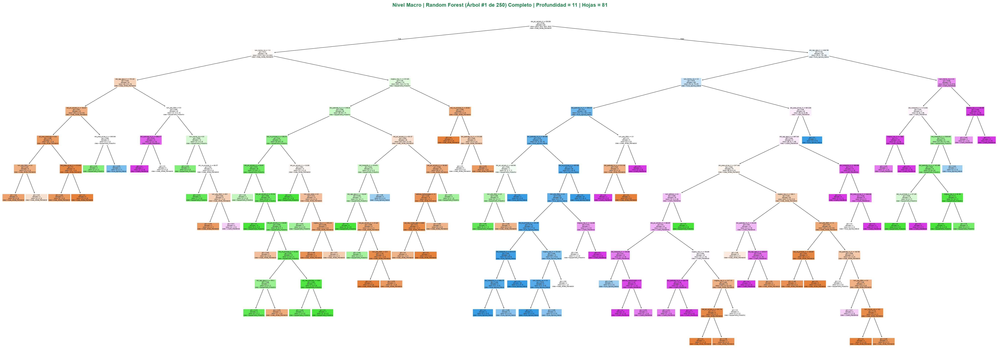

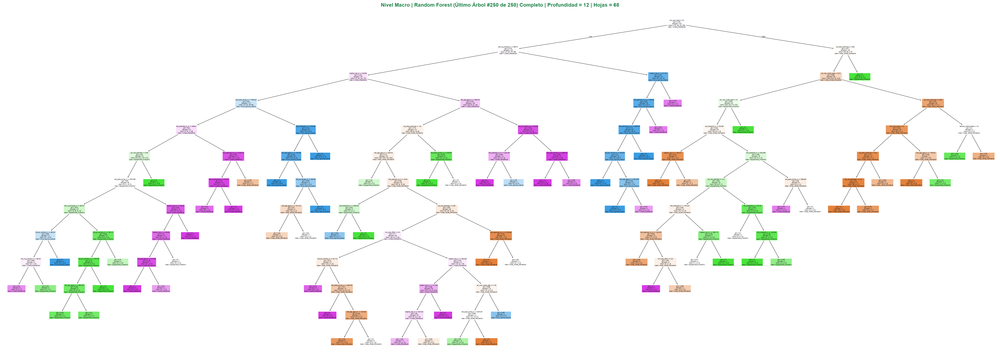

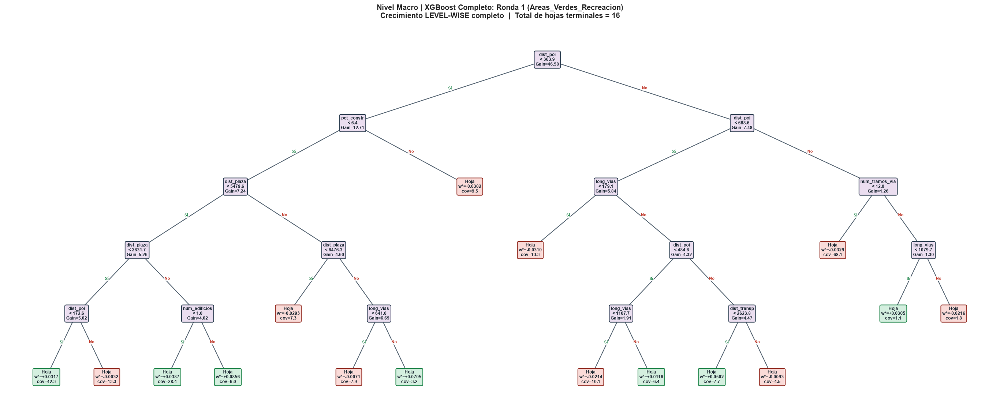

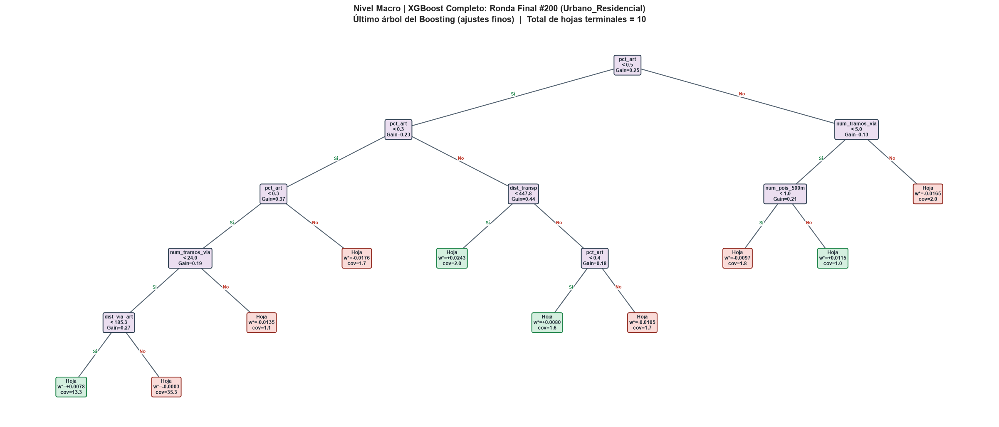

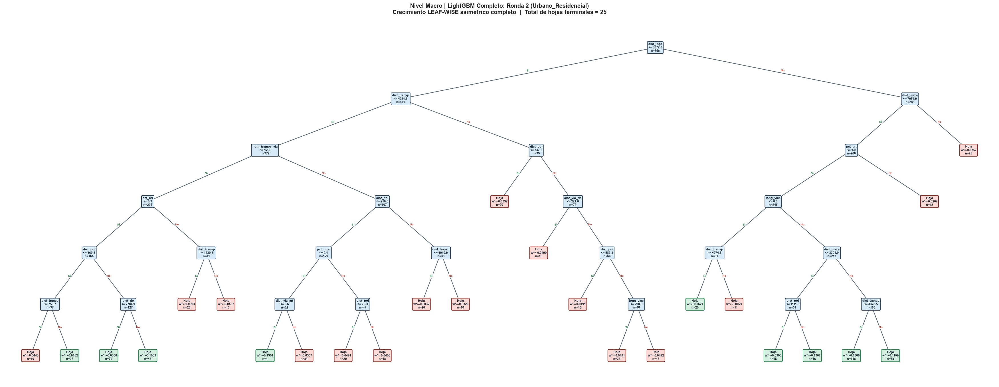

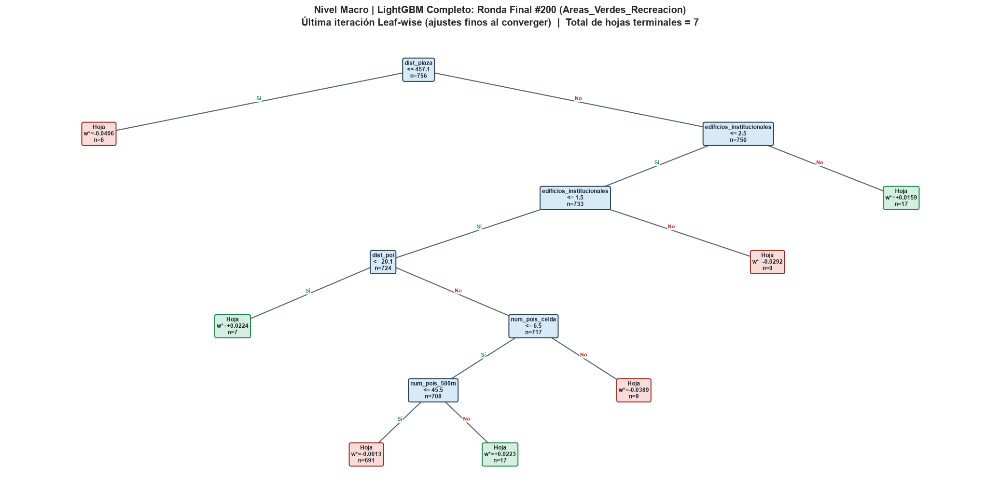

In [15]:
# 1. DecisionTree Gini y Entropía completos (Macro)
for key, col_t, fname in [
    ('DecisionTree (Gini)', '#d35400', '03_arbol_gini_completo.png'),
    ('DecisionTree (Entropía)', '#1f618d', '03_arbol_entropia_completo.png')
]:
    est = modelos_ma_fit[key]
    fig, ax = plt.subplots(figsize=(32, 13))
    plot_tree(est, feature_names=FEATURES_MACRO, class_names=clases_ma, filled=True, rounded=True, fontsize=7, ax=ax)
    ax.set_title(f"Nivel Macro | {key} Completo | Profundidad = {est.get_depth()} | Hojas = {est.get_n_leaves()}",
                 fontsize=15, fontweight='bold', color=col_t, pad=12)
    plt.tight_layout(); plt.savefig(DIR_FIGURES / fname, bbox_inches='tight', dpi=250); plt.show()

# 2. Random Forest: Árbol #1 y Árbol #250 completos (Macro)
for idx_t, fname, sub in [(0, '03_arbol_rf_001_completo.png', 'Árbol #1 de 250'), (249, '03_arbol_rf_250_completo.png', 'Último Árbol #250 de 250')]:
    est = modelos_ma_fit['Random Forest'].estimators_[idx_t]
    fig, ax = plt.subplots(figsize=(50, 18))
    plot_tree(est, feature_names=FEATURES_MACRO, class_names=clases_ma, filled=True, rounded=True, fontsize=5, ax=ax)
    ax.set_title(f"Nivel Macro | Random Forest ({sub}) Completo | Profundidad = {est.get_depth()} | Hojas = {est.get_n_leaves()}",
                 fontsize=18, fontweight='bold', color='#1e8449', pad=14)
    plt.tight_layout(); plt.savefig(DIR_FIGURES / fname, bbox_inches='tight', dpi=200); plt.show()

# 3 y 4. XGBoost (Ronda 1 y #200) y LightGBM (Ronda 2 y #200) completos (Macro)
dibujar_arbol_boosting_completo(extraer_xgb(modelos_ma_fit['XGBoost'], 0), "Nivel Macro | XGBoost Completo: Ronda 1 (Areas_Verdes_Recreacion)",
                                "Crecimiento LEVEL-WISE completo", '#ebdef0', "03_arbol_xgboost_ronda1_completo.png", (25, 10.5), 7.6)
dibujar_arbol_boosting_completo(extraer_xgb(modelos_ma_fit['XGBoost'], 799), "Nivel Macro | XGBoost Completo: Ronda Final #200 (Urbano_Residencial)",
                                "Último árbol del Boosting (ajustes finos)", '#ebdef0', "03_arbol_xgboost_ronda200_completo.png", (22, 9.5), 7.8)
dibujar_arbol_boosting_completo(extraer_lgbm(modelos_ma_fit['LightGBM'], 7), "Nivel Macro | LightGBM Completo: Ronda 2 (Urbano_Residencial)",
                                "Crecimiento LEAF-WISE asimétrico completo", '#d6eaf8', "03_arbol_lightgbm_ronda2_completo.png", (32, 12.5), 7.0)
dibujar_arbol_boosting_completo(extraer_lgbm(modelos_ma_fit['LightGBM'], 796), "Nivel Macro | LightGBM Completo: Ronda Final #200 (Areas_Verdes_Recreacion)",
                                "Última iteración Leaf-wise (ajustes finos al converger)", '#d6eaf8', "03_arbol_lightgbm_ronda200_completo.png", (19, 9.5), 8.0)

## 3.4. Matrices de Confusión 4×4, Feature Importance, Imputación y Mapa Macro

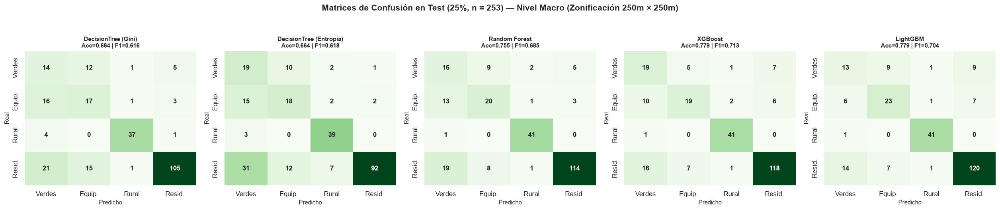

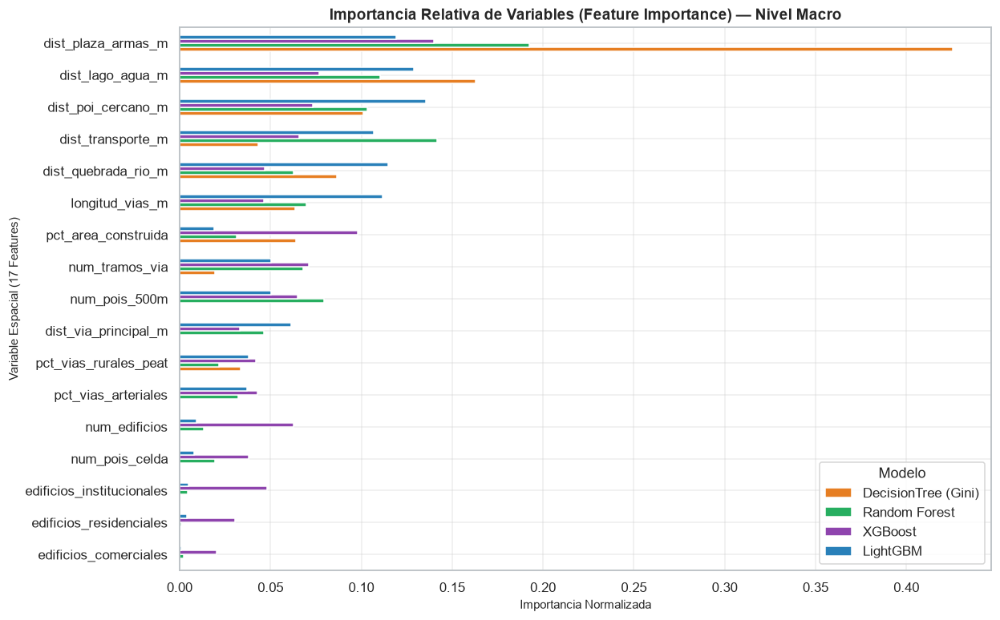

Modelo ganador Nivel Macro: XGBoost (CV-5 F1 = 0.7029)


origen_etiqueta,Predicho (ML),Verificado (OSM),All
zona_final,,,
Areas_Verdes_Recreacion,10,127,137
Equipamiento_Productivo,59,149,208
Rural_Agricola_Natural,554,167,721
Urbano_Residencial,468,566,1034
All,1091,1009,2100


In [16]:
# Matrices de Confusión 4×4 (Nivel Macro — Test n=253)
fig, axes = plt.subplots(1, 5, figsize=(23, 4.6))
for ax, (nombre, yp) in zip(axes, preds_ma_test.items()):
    cm = confusion_matrix(y_ma_test, yp)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, annot_kws={'size': 11, 'weight': 'bold'},
                xticklabels=['Verdes', 'Equip.', 'Rural', 'Resid.'], yticklabels=['Verdes', 'Equip.', 'Rural', 'Resid.'], ax=ax)
    ax.set_title(f"{nombre}\nAcc={accuracy_score(y_ma_test, yp):.3f} | F1={f1_score(y_ma_test, yp, average='macro'):.3f}", fontsize=10, fontweight='bold')
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.suptitle("Matrices de Confusión en Test (25%, n = 253) — Nivel Macro (Zonificación 250m × 250m)", fontsize=13.5, fontweight='bold', y=1.04)
plt.tight_layout(); plt.savefig(DIR_FIGURES / "03_matrices_confusion_macro.png", bbox_inches='tight'); plt.show()

# Feature Importance (Nivel Macro)
imp_ma = pd.DataFrame(index=FEATURES_MACRO)
for n in ['DecisionTree (Gini)', 'Random Forest', 'XGBoost', 'LightGBM']:
    v = modelos_ma_fit[n].feature_importances_
    imp_ma[n] = v / (v.sum() + 1e-9)
imp_ma['Prom'] = imp_ma.mean(axis=1)
imp_ma = imp_ma.sort_values('Prom', ascending=True)
imp_ma.drop(columns=['Prom']).plot(kind='barh', figsize=(11.5, 7.2), color=['#e67e22', '#27ae60', '#8e44ad', '#2980b9'], edgecolor='white')
plt.title("Importancia Relativa de Variables (Feature Importance) — Nivel Macro", fontsize=12.5, fontweight='bold')
plt.xlabel("Importancia Normalizada"); plt.ylabel("Variable Espacial (17 Features)"); plt.legend(title="Modelo", loc="lower right")
plt.tight_layout(); plt.savefig(DIR_FIGURES / "03_feature_importance_macro.png", bbox_inches='tight'); plt.show()

# Reentrenamiento con el 100% de las 1,009 verificadas e imputación de las 1,091 faltantes
nombre_ganador_ma = df_resultados_macro.iloc[0]['Modelo']
cv_f1_ganador_ma = df_resultados_macro.iloc[0]['CV-5 F1 (Macro)']
modelo_ganador_ma = crear_modelos_macro()[nombre_ganador_ma]
if nombre_ganador_ma == 'XGBoost':
    modelo_ganador_ma.fit(X_ma, y_ma, sample_weight=compute_sample_weight('balanced', y_ma))
else:
    modelo_ganador_ma.fit(X_ma, y_ma)

mask_unlab_ma = grid_activas['zona_macro'].isnull()
preds_unlab_ma = le_ma.inverse_transform(modelo_ganador_ma.predict(grid_activas.loc[mask_unlab_ma, FEATURES_MACRO]))
grid_activas['origen_etiqueta'] = np.where(mask_unlab_ma, 'Predicho (ML)', 'Verificado (OSM)')
grid_activas['zona_final'] = grid_activas['zona_macro'].copy()
grid_activas.loc[mask_unlab_ma, 'zona_final'] = preds_unlab_ma

print(f"Modelo ganador Nivel Macro: {nombre_ganador_ma} (CV-5 F1 = {cv_f1_ganador_ma:.4f})")
display(pd.crosstab(grid_activas['zona_final'], grid_activas['origen_etiqueta'], margins=True))

grid_final_wgs = grid_activas.to_crs(CRS_GEO)
grid_final_wgs.to_file(DIR_DATA_PUNO / "puno_zonificacion_macro.geojson", driver="GeoJSON")

---
# PARTE 4: Evaluación Comparativa Global, Gini vs. Entropía y Mapa Final Multiescala

## 4.1. Comparativa Global Micro vs. Macro y Trade-off Precisión vs. Velocidad

,Escala,Modelo,Paradigma,Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro),CV-5 Accuracy,CV-5 F1 (Macro),Tiempo Train (ms)
0,Nivel Micro (Edificaciones),XGBoost,Gradient Boosting,0.7826,0.7665,0.7675,0.7593,0.7540,0.7275,249.99
1,Nivel Micro (Edificaciones),Random Forest,Ensamble Bagging,0.8261,0.8343,0.8188,0.8046,0.7540,0.7264,440.41
2,Nivel Micro (Edificaciones),DecisionTree (Gini),Árbol Simple (Gini),0.7826,0.8295,0.7744,0.7498,0.7386,0.7115,1.80
3,Nivel Micro (Edificaciones),DecisionTree (Entropía),Árbol Simple (Entropía),0.7826,0.8295,0.7744,0.7498,0.7315,0.7013,1.65
4,Nivel Micro (Edificaciones),LightGBM,Leaf-wise Boosting,0.8261,0.8119,0.8085,0.8087,0.7251,0.6882,47.69
5,Nivel Macro (Zonificación),XGBoost,Gradient Boosting,0.7787,0.7095,0.7286,0.7133,0.7778,0.7029,578.65
6,Nivel Macro (Zonificación),LightGBM,Leaf-wise Boosting,0.7787,0.6966,0.7123,0.7040,0.7778,0.6991,332.94
7,Nivel Macro (Zonificación),Random Forest,Ensamble Bagging,0.7549,0.6782,0.7049,0.6854,0.7685,0.6969,700.98
8,Nivel Macro (Zonificación),DecisionTree (Gini),Árbol Simple (Gini),0.6838,0.6217,0.6293,0.6161,0.7169,0.6655,5.19
9,Nivel Macro (Zonificación),DecisionTree (Entropía),Árbol Simple (Entropía),0.6640,0.6195,0.6642,0.6179,0.7037,0.6393,9.18


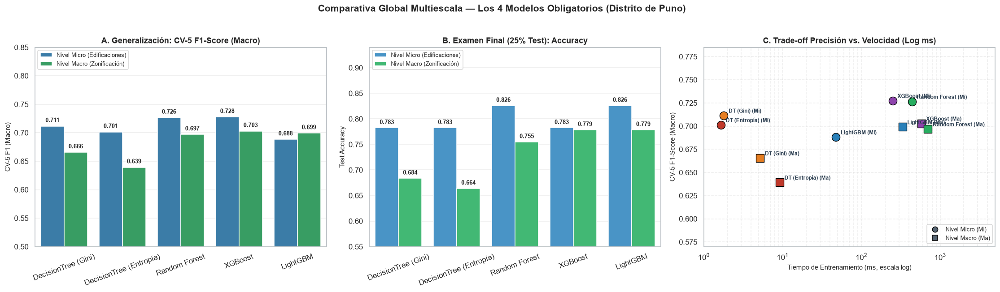

In [17]:
orden_modelos = ['DecisionTree (Gini)', 'DecisionTree (Entropía)', 'Random Forest', 'XGBoost', 'LightGBM']
paradigmas = {
    'DecisionTree (Gini)': 'Árbol Simple (Gini)', 'DecisionTree (Entropía)': 'Árbol Simple (Entropía)',
    'Random Forest': 'Ensamble Bagging', 'XGBoost': 'Gradient Boosting', 'LightGBM': 'Leaf-wise Boosting'
}

t_mi = df_resultados_micro.copy(); t_mi.insert(0, 'Escala', 'Nivel Micro (Edificaciones)')
t_ma = df_resultados_macro.copy(); t_ma.insert(0, 'Escala', 'Nivel Macro (Zonificación)')
df_global = pd.concat([t_mi, t_ma], ignore_index=True)
df_global['Paradigma'] = df_global['Modelo'].map(paradigmas)
cols_vista = ['Escala', 'Modelo', 'Paradigma', 'Test Accuracy', 'Test Precision (Macro)', 'Test Recall (Macro)',
              'Test F1 (Macro)', 'CV-5 Accuracy', 'CV-5 F1 (Macro)', 'Tiempo Train (ms)']
df_global = df_global[cols_vista]
df_global.to_csv(DIR_DATA_PUNO / "comparativa_global_modelos.csv", index=False)

display(
    df_global.style
    .format({c: "{:.4f}" for c in cols_vista[3:-1]} | {'Tiempo Train (ms)': "{:.2f}"})
    .background_gradient(subset=['CV-5 F1 (Macro)', 'Test F1 (Macro)'], cmap='YlGn')
    .set_caption("Tabla Consolidada Global — Micro vs. Macro (4 Modelos Obligatorios)")
)

fig, axes = plt.subplots(1, 3, figsize=(20.5, 5.8))
sns.barplot(data=df_global, x='Modelo', y='CV-5 F1 (Macro)', hue='Escala', order=orden_modelos, palette=['#2980b9', '#27ae60'], edgecolor='white', ax=axes[0])
axes[0].set_title("A. Generalización: CV-5 F1-Score (Macro)"); axes[0].set_ylim(0.50, 0.85); axes[0].tick_params(axis='x', rotation=20); axes[0].set_xlabel(""); axes[0].legend(title="", loc='upper left', fontsize=8.5)
for p in axes[0].patches:
    if p.get_height() > 0:
        axes[0].annotate(f"{p.get_height():.3f}", (p.get_x()+p.get_width()/2, p.get_height()+0.005), ha='center', va='bottom', fontsize=8.2, fontweight='bold')

sns.barplot(data=df_global, x='Modelo', y='Test Accuracy', hue='Escala', order=orden_modelos, palette=['#3498db', '#2ecc71'], edgecolor='white', ax=axes[1])
axes[1].set_title("B. Examen Final (25% Test): Accuracy"); axes[1].set_ylim(0.55, 0.94); axes[1].tick_params(axis='x', rotation=20); axes[1].set_xlabel(""); axes[1].legend(title="", loc='upper left', fontsize=8.5)
for p in axes[1].patches:
    if p.get_height() > 0:
        axes[1].annotate(f"{p.get_height():.3f}", (p.get_x()+p.get_width()/2, p.get_height()+0.005), ha='center', va='bottom', fontsize=8.2, fontweight='bold')

colores_mod = {'DecisionTree (Gini)': '#e67e22', 'DecisionTree (Entropía)': '#c0392b', 'Random Forest': '#27ae60', 'XGBoost': '#8e44ad', 'LightGBM': '#2980b9'}
for _, row in df_global.iterrows():
    esc_tag = 'Mi' if 'Micro' in row['Escala'] else 'Ma'
    axes[2].scatter(row['Tiempo Train (ms)'], row['CV-5 F1 (Macro)'], s=140, color=colores_mod[row['Modelo']],
                    marker='o' if esc_tag == 'Mi' else 's', edgecolors='black', linewidth=0.9, zorder=3)
    axes[2].annotate(f"{row['Modelo'].replace('DecisionTree ', 'DT ')} ({esc_tag})", (row['Tiempo Train (ms)'], row['CV-5 F1 (Macro)']),
                     textcoords="offset points", xytext=(7, 4), fontsize=7.8, fontweight='bold', color='#2c3e50')
axes[2].set_xscale('log'); axes[2].set_xlim(1.0, 5000); axes[2].set_ylim(0.57, 0.785)
axes[2].set_title("C. Trade-off Precisión vs. Velocidad (Log ms)"); axes[2].set_xlabel("Tiempo de Entrenamiento (ms, escala log)"); axes[2].set_ylabel("CV-5 F1-Score (Macro)")
axes[2].grid(True, which="both", ls="--", alpha=0.35)
axes[2].legend(handles=[
    Line2D([0], [0], marker='o', color='w', label='Nivel Micro (Mi)', markerfacecolor='#566573', markeredgecolor='black', markersize=8),
    Line2D([0], [0], marker='s', color='w', label='Nivel Macro (Ma)', markerfacecolor='#566573', markeredgecolor='black', markersize=8)
], loc='lower right', fontsize=8.5, frameon=True, facecolor='white')

plt.suptitle("Comparativa Global Multiescala — Los 4 Modelos Obligatorios (Distrito de Puno)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig(DIR_FIGURES / "04_comparativa_global_modelos.png", bbox_inches='tight'); plt.show()

## 4.2. Curvas Gini vs. Entropía (Sobreajuste), Concordancia (Kappa) y Coherencia Multiescala

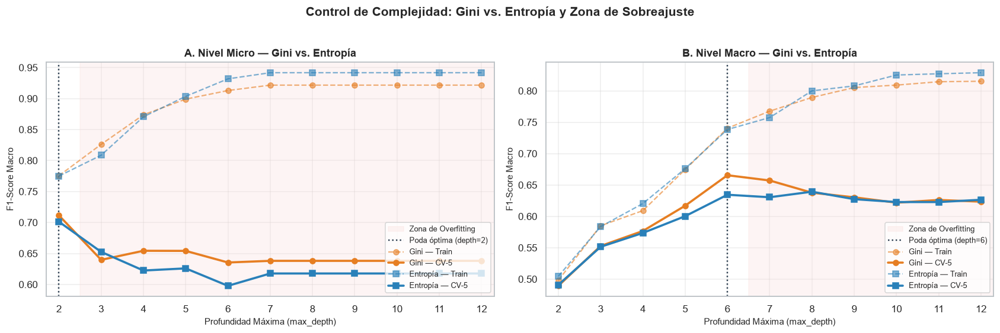

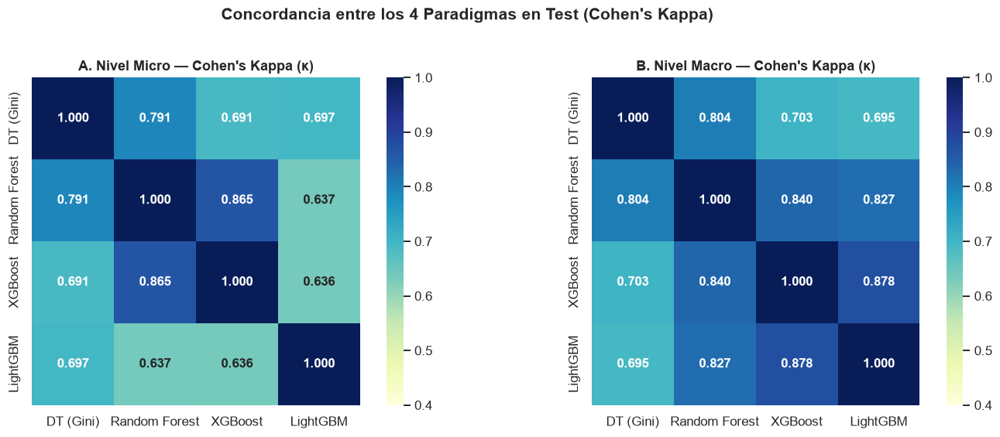

,Micro (n=46),Micro (%),Macro (n=253),Macro (%)
estado_eval,,,,
Acierto Unánime (4/4),31,67.4,158,62.5
Discrepancia entre Modelos,12,26.1,56,22.1
Error Unánime (0/4),3,6.5,39,15.4


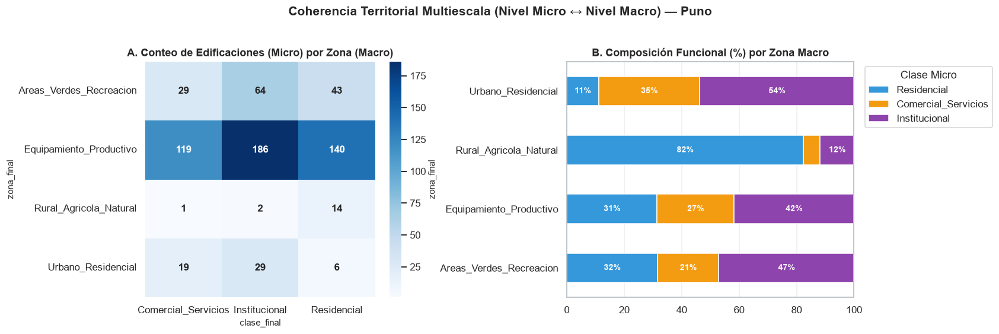

In [18]:
# 1. Curvas Train vs CV-5 (Gini vs Entropía) en Micro y Macro
depths = list(range(2, 13))
def curvas_ge(X_tr, y_tr, min_leaf, cw=None):
    h = {c: {'tr': [], 'cv': []} for c in ['gini', 'entropy']}
    for crit in ['gini', 'entropy']:
        for d in depths:
            tf, vf = [], []
            for ti, vi in cv.split(X_tr, y_tr):
                clf = DecisionTreeClassifier(criterion=crit, max_depth=d, min_samples_leaf=min_leaf, class_weight=cw, random_state=42).fit(X_tr.iloc[ti], y_tr[ti])
                tf.append(f1_score(y_tr[ti], clf.predict(X_tr.iloc[ti]), average='macro'))
                vf.append(f1_score(y_tr[vi], clf.predict(X_tr.iloc[vi]), average='macro'))
            h[crit]['tr'].append(np.mean(tf)); h[crit]['cv'].append(np.mean(vf))
    return h

h_mi = curvas_ge(X_mi_train, y_mi_train, 3, None)
h_ma = curvas_ge(X_ma_train, y_ma_train, 5, 'balanced')

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.0))
for ax, h, od, tit in [(axes[0], h_mi, mejor_d_g_mi, "A. Nivel Micro — Gini vs. Entropía"), (axes[1], h_ma, mejor_d_g_ma, "B. Nivel Macro — Gini vs. Entropía")]:
    ax.axvspan(od + 0.5, 12.3, color='#fadbd8', alpha=0.28, label='Zona de Overfitting')
    ax.axvline(od, color='#2c3e50', linestyle=':', linewidth=1.6, label=f'Poda óptima (depth={od})')
    ax.plot(depths, h['gini']['tr'], 'o--', color='#e67e22', alpha=0.6, label='Gini — Train')
    ax.plot(depths, h['gini']['cv'], 'o-', color='#e67e22', linewidth=2.4, label='Gini — CV-5')
    ax.plot(depths, h['entropy']['tr'], 's--', color='#2980b9', alpha=0.6, label='Entropía — Train')
    ax.plot(depths, h['entropy']['cv'], 's-', color='#2980b9', linewidth=2.4, label='Entropía — CV-5')
    ax.set_title(tit); ax.set_xlabel("Profundidad Máxima (max_depth)"); ax.set_ylabel("F1-Score Macro"); ax.set_xticks(depths); ax.set_xlim(1.7, 12.3)
    ax.legend(fontsize=8.2, loc='lower right', frameon=True, facecolor='white')
plt.suptitle("Control de Complejidad: Gini vs. Entropía y Zona de Sobreajuste", fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig(DIR_FIGURES / "04_gini_vs_entropia_curvas.png", bbox_inches='tight'); plt.show()

# 2. Acuerdo entre Modelos (Cohen's Kappa) + Aciertos Unánimes vs Discrepancias
familias = ['DecisionTree (Gini)', 'Random Forest', 'XGBoost', 'LightGBM']
cortos = ['DT (Gini)', 'Random Forest', 'XGBoost', 'LightGBM']

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
for ax, pr, tit in [(axes[0], preds_mi_test, "A. Nivel Micro — Cohen's Kappa (κ)"), (axes[1], preds_ma_test, "B. Nivel Macro — Cohen's Kappa (κ)")]:
    mat = pd.DataFrame([[cohen_kappa_score(pr[f1], pr[f2]) for f2 in familias] for f1 in familias], index=cortos, columns=cortos)
    sns.heatmap(mat, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.4, vmax=1.0, annot_kws={'size': 11, 'weight': 'bold'}, ax=ax, square=True)
    ax.set_title(tit)
plt.suptitle("Concordancia entre los 4 Paradigmas en Test (Cohen's Kappa)", fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig(DIR_FIGURES / "04_acuerdo_modelos_kappa.png", bbox_inches='tight'); plt.show()

def eval_aciertos(df_lab, X_te, y_te, preds, le, id_col, extra=None):
    out = df_lab.loc[X_te.index, [id_col] + (extra or [])].copy()
    out['Real'] = le.inverse_transform(y_te)
    for cs, mn in [('DT', 'DecisionTree (Gini)'), ('RF', 'Random Forest'), ('XGB', 'XGBoost'), ('LGBM', 'LightGBM')]:
        out[cs] = le.inverse_transform(preds[mn])
    ac = sum((out[c] == out['Real']).astype(int) for c in ['DT', 'RF', 'XGB', 'LGBM'])
    out['estado_eval'] = np.select([ac == 4, ac == 0], ['Acierto Unánime (4/4)', 'Error Unánime (0/4)'], default='Discrepancia entre Modelos')
    return out

eval_mi = eval_aciertos(df_mi_lab, X_mi_test, y_mi_test, preds_mi_test, le_mi, 'osm_id', ['name'])
eval_ma = eval_aciertos(df_ma_lab, X_ma_test, y_ma_test, preds_ma_test, le_ma, 'cell_id')

orden_est = ['Acierto Unánime (4/4)', 'Discrepancia entre Modelos', 'Error Unánime (0/4)']
res_est = pd.DataFrame({
    'Micro (n=46)': eval_mi['estado_eval'].value_counts().reindex(orden_est, fill_value=0),
    'Micro (%)': (eval_mi['estado_eval'].value_counts(normalize=True).reindex(orden_est, fill_value=0) * 100).round(1),
    'Macro (n=253)': eval_ma['estado_eval'].value_counts().reindex(orden_est, fill_value=0),
    'Macro (%)': (eval_ma['estado_eval'].value_counts(normalize=True).reindex(orden_est, fill_value=0) * 100).round(1)
})
display(res_est)

# 3. Coherencia Multiescala (652 edificios × 4 zonas Macro)
cruce = gpd.sjoin(b_cent_m[['clase_final', 'geometry']], grid_activas[['cell_id', 'zona_final', 'geometry']], how='inner', predicate='within')
ct_abs = pd.crosstab(cruce['zona_final'], cruce['clase_final'], margins=True)
ct_pct = pd.crosstab(cruce['zona_final'], cruce['clase_final'], normalize='index') * 100
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.0))
sns.heatmap(ct_abs.drop(index='All', columns='All'), annot=True, fmt='d', cmap='Blues', annot_kws={'size': 11, 'weight': 'bold'}, ax=axes[0])
axes[0].set_title("A. Conteo de Edificaciones (Micro) por Zona (Macro)")
ct_pct[['Residencial', 'Comercial_Servicios', 'Institucional']].plot(kind='barh', stacked=True, color=['#3498db', '#f39c12', '#8e44ad'], ax=axes[1], edgecolor='white')
axes[1].set_title("B. Composición Funcional (%) por Zona Macro"); axes[1].set_xlim(0, 100); axes[1].legend(title="Clase Micro", bbox_to_anchor=(1.02, 1), loc='upper left')
for cont in axes[1].containers:
    axes[1].bar_label(cont, labels=[f"{v:.0f}%" if v >= 10 else "" for v in cont.datavalues], label_type='center', color='white', fontsize=9, fontweight='bold')
plt.suptitle("Coherencia Territorial Multiescala (Nivel Micro ↔ Nivel Macro) — Puno", fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig(DIR_FIGURES / "04_coherencia_multiescala.png", bbox_inches='tight'); plt.show()

## 4.3. Lámina Cartográfica Final Clasificada y Mapa Interactivo Integrado Multiescala

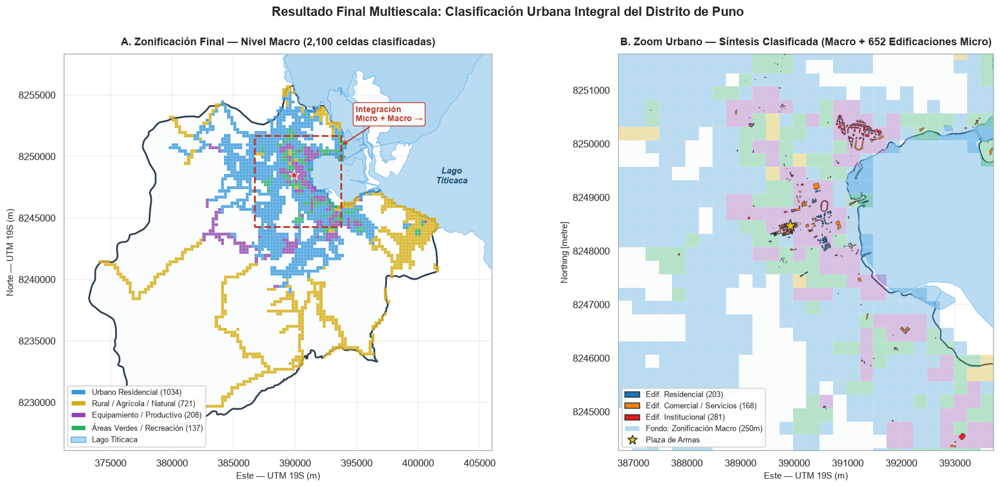

In [19]:
# Lámina Cartográfica Final Clasificada (Macro Distrital + Zoom Integrado Micro+Macro)
colores_micro_final = {'Residencial': '#1f77b4', 'Comercial_Servicios': '#ff7f0e', 'Institucional': '#e31a1c'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 7.6), gridspec_kw={'width_ratios': [1.05, 1]})

puno_utm.plot(ax=ax1, color='#fbfcfc', edgecolor='#2c3e50', linewidth=1.9, zorder=1)
wa_utm.plot(ax=ax1, color='#aed6f1', edgecolor='#5dade2', linewidth=0.6, alpha=0.85, zorder=2)
for zona, col in colores_zonas_map.items():
    grid_activas[grid_activas['zona_final'] == zona].plot(ax=ax1, color=col, edgecolor='white', linewidth=0.15, alpha=0.82, zorder=3)
ax1.add_patch(Rectangle((zoom_minx, zoom_miny), zoom_maxx - zoom_minx, zoom_maxy - zoom_miny,
                        linewidth=2.0, edgecolor='#c0392b', facecolor='none', linestyle='--', zorder=5))
ax1.scatter([px], [py], color='#c0392b', marker='*', s=140, edgecolor='white', linewidth=0.8, zorder=6)
ax1.set_xlim(bminx - 2000, bmaxx + 4500); ax1.set_ylim(bminy - 2000, bmaxy + 2500)
ax1.annotate("Integración\nMicro + Macro →", xy=(zoom_maxx, zoom_maxy - 800), xytext=(zoom_maxx + 1200, zoom_maxy + 1200),
             fontsize=9.2, fontweight='bold', color='#c0392b',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#c0392b', alpha=0.93),
             arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.4))
ax1.text(bmaxx + 1200, bmaxy - 8000, "Lago\nTiticaca", fontsize=10, style='italic', fontweight='bold', color='#1b4f72', ha='center', zorder=6)
ax1.set_title("A. Zonificación Final — Nivel Macro (2,100 celdas clasificadas)", pad=10)
ax1.set_xlabel("Este — UTM 19S (m)"); ax1.set_ylabel("Norte — UTM 19S (m)"); ax1.ticklabel_format(style='plain', axis='both')
cnt_ma_c = grid_activas['zona_final'].value_counts()
ax1.legend(handles=[
    mpatches.Patch(facecolor='#3498db', label=f"Urbano Residencial ({int(cnt_ma_c.get('Urbano_Residencial', 0))})"),
    mpatches.Patch(facecolor='#d4ac0d', label=f"Rural / Agrícola / Natural ({int(cnt_ma_c.get('Rural_Agricola_Natural', 0))})"),
    mpatches.Patch(facecolor='#8e44ad', label=f"Equipamiento / Productivo ({int(cnt_ma_c.get('Equipamiento_Productivo', 0))})"),
    mpatches.Patch(facecolor='#27ae60', label=f"Áreas Verdes / Recreación ({int(cnt_ma_c.get('Areas_Verdes_Recreacion', 0))})"),
    mpatches.Patch(facecolor='#aed6f1', edgecolor='#5dade2', label='Lago Titicaca')
], loc='lower left', fontsize=8.4, frameon=True, facecolor='white', framealpha=0.94)

puno_utm.plot(ax=ax2, color='#fbfcfc', edgecolor='#2c3e50', linewidth=1.5, zorder=1)
wa_utm.plot(ax=ax2, color='#aed6f1', edgecolor='#5dade2', linewidth=0.6, alpha=0.85, zorder=2)
for zona, col in colores_zonas_map.items():
    grid_activas[grid_activas['zona_final'] == zona].plot(ax=ax2, color=col, edgecolor='white', linewidth=0.25, alpha=0.32, zorder=3)
for clase, col in colores_micro_final.items():
    b_utm[b_utm['clase_final'] == clase].plot(ax=ax2, color=col, edgecolor='#1c2833', linewidth=0.35, alpha=0.95, zorder=5)
ax2.scatter([px], [py], color='#f1c40f', marker='*', s=210, edgecolor='#1c2833', linewidth=0.9, zorder=7)
ax2.set_xlim(zoom_minx, zoom_maxx); ax2.set_ylim(zoom_miny, zoom_maxy)
ax2.set_title("B. Zoom Urbano — Síntesis Clasificada (Macro + 652 Edificaciones Micro)", pad=10)
ax2.set_xlabel("Este — UTM 19S (m)"); ax2.ticklabel_format(style='plain', axis='both')
cnt_mi_c = b_utm['clase_final'].value_counts()
ax2.legend(handles=[
    mpatches.Patch(facecolor='#1f77b4', edgecolor='#1c2833', label=f"Edif. Residencial ({int(cnt_mi_c.get('Residencial', 0))})"),
    mpatches.Patch(facecolor='#ff7f0e', edgecolor='#1c2833', label=f"Edif. Comercial / Servicios ({int(cnt_mi_c.get('Comercial_Servicios', 0))})"),
    mpatches.Patch(facecolor='#e31a1c', edgecolor='#1c2833', label=f"Edif. Institucional ({int(cnt_mi_c.get('Institucional', 0))})"),
    mpatches.Patch(facecolor='#3498db', alpha=0.35, label='Fondo: Zonificación Macro (250m)'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#f1c40f', markeredgecolor='#1c2833', markersize=11, label='Plaza de Armas')
], loc='lower left', fontsize=8.3, frameon=True, facecolor='white', framealpha=0.94)

plt.suptitle("Resultado Final Multiescala: Clasificación Urbana Integral del Distrito de Puno", fontsize=14.5, fontweight='bold', y=0.99)
plt.tight_layout(); plt.savefig(DIR_FIGURES / "04_mapa_final_multiescala.png", bbox_inches='tight'); plt.show()

In [20]:
# Mapa Interactivo Final Integrado (Zonificación Macro + Edificaciones Micro + Aciertos/Discrepancias)
colores_eval = {'Acierto Unánime (4/4)': '#2ecc71', 'Discrepancia entre Modelos': '#f39c12', 'Error Unánime (0/4)': '#e74c3c'}

eval_mi_m = eval_mi.copy(); eval_mi_m['osm_id'] = eval_mi_m['osm_id'].astype(str)
b_merge = b_final_wgs84[['osm_id', 'geometry']].copy(); b_merge['osm_id'] = b_merge['osm_id'].astype(str)
gdf_test_ma = grid_final_wgs[['cell_id', 'geometry']].merge(eval_ma, on='cell_id', how='inner')
gdf_test_mi = b_merge.merge(eval_mi_m, on='osm_id', how='inner'); gdf_test_mi['name'] = gdf_test_mi['name'].fillna('Sin nombre')

m_final = folium.Map(location=[-15.8402, -70.0280], zoom_start=14, tiles="OpenStreetMap")
Fullscreen(position='topright').add_to(m_final)
MiniMap(toggle_display=True, minimized=True).add_to(m_final)

folium.GeoJson(puno_distrito, name="Límite Distrito de Puno",
               style_function=lambda x: {'fillColor': 'none', 'color': '#2c3e50', 'weight': 2.2, 'dashArray': '6, 4'}).add_to(m_final)

fg_ma = folium.FeatureGroup(name="Nivel Macro: Zonificación (2,100 celdas)", show=True)
sm = grid_final_wgs[['zona_final', 'origen_etiqueta', 'longitud_vias_m', 'num_edificios', 'geometry']].copy()
sm['longitud_vias_m'] = sm['longitud_vias_m'].round(1); sm['num_edificios'] = sm['num_edificios'].astype(int)
folium.GeoJson(
    sm,
    style_function=lambda f: {'fillColor': colores_zonas_map.get(f['properties']['zona_final'], '#95a5a6'),
                              'color': colores_zonas_map.get(f['properties']['zona_final'], '#95a5a6'), 'weight': 0.4, 'fillOpacity': 0.34},
    tooltip=folium.GeoJsonTooltip(fields=['zona_final', 'origen_etiqueta', 'longitud_vias_m', 'num_edificios'],
                                  aliases=['Zona Macro:', 'Origen:', 'Long. Vías (m):', 'N° Edificios:'], localize=True)
).add_to(fg_ma); fg_ma.add_to(m_final)

fg_mi = folium.FeatureGroup(name="Nivel Micro: Edificaciones (652 edificios)", show=True)
sb = b_final_wgs84[['name', 'clase_final', 'origen_etiqueta', 'area_m2', 'geometry']].copy()
sb['name'] = sb['name'].fillna('Sin nombre'); sb['area_m2'] = sb['area_m2'].round(1)
folium.GeoJson(
    sb,
    style_function=lambda f: {'fillColor': colores_micro_final.get(f['properties']['clase_final'], '#7f8c8d'),
                              'color': '#1c2833', 'weight': 0.8, 'fillOpacity': 0.88},
    tooltip=folium.GeoJsonTooltip(fields=['name', 'clase_final', 'origen_etiqueta', 'area_m2'],
                                  aliases=['Edificio:', 'Clase Micro:', 'Origen:', 'Área (m²):'], localize=True)
).add_to(fg_mi); fg_mi.add_to(m_final)

fg_dma = folium.FeatureGroup(name="Test Macro: Aciertos y Discrepancias (253 celdas)", show=False)
folium.GeoJson(
    gdf_test_ma[['cell_id', 'estado_eval', 'Real', 'DT', 'RF', 'XGB', 'LGBM', 'geometry']],
    style_function=lambda f: {'fillColor': colores_eval.get(f['properties']['estado_eval'], '#95a5a6'),
                              'color': '#2c3e50', 'weight': 1.2, 'fillOpacity': 0.65},
    tooltip=folium.GeoJsonTooltip(fields=['estado_eval', 'Real', 'DT', 'RF', 'XGB', 'LGBM'],
                                  aliases=['Resultado:', 'Real (OSM):', 'DT (Gini):', 'Random Forest:', 'XGBoost:', 'LightGBM:'])
).add_to(fg_dma); fg_dma.add_to(m_final)

fg_dmi = folium.FeatureGroup(name="Test Micro: Aciertos y Discrepancias (46 edificios)", show=True)
cent_tmi = gdf_test_mi.to_crs(CRS_METRICO).geometry.centroid.to_crs(CRS_GEO)
for idx, row in gdf_test_mi.iterrows():
    pt = cent_tmi.loc[idx]
    popup_html = (f"<b>{row['name']}</b><br><b>Estado:</b> {row['estado_eval']}<br><b>Real (OSM):</b> {row['Real']}<br>"
                  f"<b>DT (Gini):</b> {row['DT']}<br><b>RF:</b> {row['RF']}<br><b>XGB:</b> {row['XGB']}<br><b>LGBM:</b> {row['LGBM']}")
    folium.CircleMarker([pt.y, pt.x], radius=6.5, color='#1c2833', weight=1.3, fill=True,
                        fill_color=colores_eval[row['estado_eval']], fill_opacity=0.92,
                        tooltip=f"{row['name']} — {row['estado_eval']}", popup=folium.Popup(popup_html, max_width=280)).add_to(fg_dmi)
fg_dmi.add_to(m_final)

leyenda_html = '''
<div style="position: fixed; bottom: 25px; left: 25px; z-index: 9999; background: rgba(255,255,255,0.96);
            padding: 12px 15px; border: 1.5px solid #2c3e50; border-radius: 8px; font-size: 11.8px;
            box-shadow: 0 3px 10px rgba(0,0,0,0.24); line-height: 1.48;">
  <div style="font-weight: bold; font-size: 13px; color: #1c2833; border-bottom: 1px solid #d5d8dc; padding-bottom: 4px; margin-bottom: 5px;">
    Mapa Final Multiescala — Puno
  </div>
  <b>Zonas Macro (250m × 250m):</b><br>
  <span style="color:#3498db;">■</span> Urbano Residencial &nbsp; <span style="color:#d4ac0d;">■</span> Rural/Agrícola<br>
  <span style="color:#8e44ad;">■</span> Equip./Productivo &nbsp; <span style="color:#27ae60;">■</span> Áreas Verdes<br>
  <b>Edificaciones Micro (652):</b><br>
  <span style="color:#1f77b4;">■</span> Residencial &nbsp; <span style="color:#ff7f0e;">■</span> Comercial &nbsp; <span style="color:#e31a1c;">■</span> Institucional<br>
  <b>Evaluación Test (Aciertos/Discrepancias):</b><br>
  <span style="color:#2ecc71;">●</span> Acierto 4/4 &nbsp; <span style="color:#f39c12;">●</span> Discrepancia &nbsp; <span style="color:#e74c3c;">●</span> Error 0/4
</div>
'''
m_final.get_root().html.add_child(folium.Element(leyenda_html))
folium.LayerControl(collapsed=False).add_to(m_final)
m_final.save(DIR_DATA_PUNO / "mapa_final_multiescala_puno.html")
print(f"Mapa final guardado en: {(DIR_DATA_PUNO / 'mapa_final_multiescala_puno.html').resolve()}")
m_final

Mapa final guardado en: C:\Users\ronim\.gemini\antigravity\brain\78f47f65-46bb-41da-8f4c-8528604246a0\scratch\colab_sandbox\data_puno\mapa_final_multiescala_puno.html


## 4.4. Conclusiones Finales del Proyecto (Unidad 2 — EDA)

1. **Superioridad de los Ensambles frente al Árbol Simple (Partición 75/25 + 5-Fold CV sobre 75% Train):**
   * **Nivel Micro (`652` edificaciones, 3 clases):** **XGBoost** lidera en generalización (`CV-5 F1 Macro = 0.7275`) seguido muy de cerca por **Random Forest** (`0.7264`), mientras que **LightGBM** (`F1 Macro = 0.8087`, `Accuracy = 0.8261`) y **Random Forest** (`F1 Macro = 0.8046`, `Accuracy = 0.8261`) encabezan el examen final (`25% Test, n = 46`).
   * **Nivel Macro (`2,100` celdas de $250\text{ m} \times 250\text{ m}$, 4 clases balanceadas):** **XGBoost** lidera tanto en `CV-5 F1 Macro` (`0.7029`) como en el examen final (`25% Test, n = 253`: `Test Accuracy = 0.7787`, `F1 Macro = 0.7133`), seguido por **LightGBM** (`CV-5 F1 = 0.6991`, `Test F1 = 0.7040`) y **Random Forest** (`CV-5 F1 = 0.6969`).
2. **Gini vs. Entropía y Control de Poda (`max_depth`):**
   * Las curvas *Train vs. CV-5* evidencian con precisión el umbral de *overfitting* (`depth > 2` en Micro y `depth > 6` en Macro para Gini). En Macro, **Gini** logra un árbol más compacto (`25` hojas) y mejor generalización (`0.6655`) que **Entropía** (`51` hojas, `0.6393`).
3. **Estructuras Espaciales (`cKDTree`) y Enfoque Multiescala:**
   * El uso de `cKDTree` ($O(\log N)$) y el puente **Micro → Macro** generaron alta concordancia entre modelos (`67.4%` de acierto unánime en Micro y `62.5%` en Macro) y coherencia territorial verificable sobre el Distrito de Puno.